<a href="https://colab.research.google.com/github/foner21/AISE4010_Section4_Group5/blob/main/aise4010_section4group5_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**Room Occupancy Estimation Using Time-Series Machine Learning and Deep Learning**
**AISE4010 - Group 5**

*Comparative Evaluation of Traditional Machine Learning, Feedforward Neural Networks, Convolutional Models, Recurrent Networks, and Temporal Convolutional Networks*

**Group members:** Fiona Oner, Stephanie Ndefo, Rebecca Fry, Aala Hamza

**Dataset:** UCI Room Occupancy Estimation

**Project focus:** Multivariate time-series classification and short-term occupancy forecasting

#**Room Occupancy Estimation Using Time-Series Machine Learning and Deep Learning**
**AISE 4010 — Group 5**

**Labs 1–2 + Stage 1 preparation (traditional baselines, MLP, CNN, grid search) + Stage 2 preperation ( RNN, LSTM/GRU, and TCN models)**

**Group:** 5
**Members:** Fiona Oner, Stephanie Ndefo, Rebecca Fry, Aala Hamza
**Dataset:** [UCI Room Occupancy Estimation (#15)](https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation)


___

##**Table of Contents**
1. Introction and Problem Definition
   - *Project objective, forecasting task, dataset, target variable and experimental scope.*
2. Dataset Overview and Timestamp Audit
   - *Dataset dimensions, sensor descriptions, sampling frequency, missing values, duplicate timestamps and temporal gaps.*
3. Exploratory Data Analysis
    - *Occupancy distribution, occupancy over time, CO₂ trends and sensor distributions.*
4. Temporal Data Splitting and Validation Strategy
    - *Chronological partitions, class coverage, gap diagnostics and leakage prevention.*
5. Data Preprocessing and Feature Engineering
    - *Missing-value imputation, scaling, calendar features and removal of potentially leaky features.*
6. Supervised Learning Dataset Construction
    - *Lookback window, prediction horizon, window generation and class distributions.*
7. Traditional Machine Learning Baselines
    - *Majority-class, persistence and Random Forest models.
8. Feedforward and Convolutional Neural Networks
    - *MLP and CNN architectures, training results and learning curves.*
9. Recurrent Neural Network Models
    - *SimpleRNN, LSTM and GRU architectures and comparative performance.*
10. Temporal Convolutional Network
    - *TCN architecture, causal convolutions, dilation and receptive field.*
11. Hyperparameter Optimization
    - *Search spaces, trial budgets, optimization objectives, early stopping and trial comparisons.*
12. Comprehensive Model Comparison
    - *Validation metrics, parameter counts, training time, inference time and model selection.*
13. Discussion, Limitations and Future Improvements
    - *Interpretation of results, class imbalance, temporal persistence and future experiments.*

---

## 1. Problem definition (Lab 1)
**Objective:** predict the **number of people in the room** (`Room_Occupancy_Count`) using multivariate historical sensor measurements, historical occupancy labels and known-in-advance calendar variables. Target unit: *people* (integer class), so this is multi-class classification rather than continuous regression.

**Native frequency:** expected 30 seconds, verified below. **Resampling rule:** no resampling in the initial pipeline to preserve short occupancy transitions. **Lookback:** 20 records (10 minutes). **Forecast horizon:** 2 records (1 minute after the latest input measurement).

**Operational application:** anticipate occupancy for building HVAC/ventilation and lighting management. **Leakage policy:**

**Limitations:** extremely short observation period and potential class shifts across chronological partitions. Any candidate CO₂ slope using future observations is excluded; a strictly past-only derived slope can be added in future experiments.

In [ ]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

In [ ]:
# initialization and configuration , establishing reporducibility
import os, io, zipfile, urllib.request, warnings, time, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42 # to allow for consistent reproducibility
random.seed(SEED); np.random.seed(SEED)
EXPECTED_FREQ = pd.Timedelta(seconds=30) #
#each prediction uses 20 past observation
LOOKBACK = 20
#predicting occupancy count two observations after the most recent input
HORIZON = 2
TARGET = 'Room_Occupancy_Count' # four occupancy classes
#enabling neural networks

RUN_DEEP_MODELS = True  # change to False to complete Labs 1-2 faster
# enabling hyperparemeter search
RUN_GRID_SEARCH = True  # grid-search one of the Stage 1 neural models
RUN_FINAL_TEST = False  # do not change without clearance to run final test
DATA_DIR = Path('data'); DATA_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
print('Working directory:', Path.cwd())

Working directory: /content


In [ ]:
# Download official UCI archive, extract the occupancy CSV, otherwise prompt for upload.
csv_path = DATA_DIR / 'Occupancy_Estimation.csv'
uci_archive = 'https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip'
if not csv_path.exists():
    try:
        request = urllib.request.Request(uci_archive, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=45) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            names = [name for name in archive.namelist() if name.lower().endswith('.csv') and not name.startswith('__MACOSX')]
            print('CSV members in archive:', names)
            candidates = [name for name in names if 'occupancy' in name.lower()]
            if not candidates: raise ValueError('Expected occupancy CSV not found in downloaded zip')
            with archive.open(candidates[0]) as src:
                csv_path.write_bytes(src.read())
        print('Dataset saved to:', csv_path)
    except Exception as exc:
        print('Automatic download failed:', repr(exc))
        print('Download the CSV from the UCI dataset page and upload it in the prompt.')
        try:
            from google.colab import files
            uploaded = files.upload()
            csv_candidates = [(name, contents) for name, contents in uploaded.items() if name.lower().endswith('.csv')]
            if not csv_candidates: raise RuntimeError('Please upload a CSV file, then rerun this cell.')
            csv_path.write_bytes(csv_candidates[0][1])
        except ImportError:
            raise RuntimeError('Place Occupancy_Estimation.csv in the local data/ folder.') from exc
assert csv_path.exists(), 'Dataset file still missing'
print('Bytes:', csv_path.stat().st_size)

CSV members in archive: ['Occupancy_Estimation.csv']
Dataset saved to: data/Occupancy_Estimation.csv
Bytes: 931630


In [ ]:
#establishing the number of observations, columns and occupancy classes
raw = pd.read_csv(csv_path)
raw.columns = raw.columns.str.strip()
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head(8))
print('\nDtypes:'); display(raw.dtypes.to_frame('dtype'))
required = {'Date', 'Time', TARGET}
assert required.issubset(raw.columns), f'Missing expected columns: {required - set(raw.columns)}'
raw['timestamp'] = pd.to_datetime(raw['Date'].astype(str) + ' ' + raw['Time'].astype(str), errors='coerce')
invalid_ts = int(raw['timestamp'].isna().sum())
if invalid_ts: print(f'WARNING: {invalid_ts} unparseable timestamps; these rows will be excluded after audit.')
df = raw.dropna(subset=['timestamp']).sort_values('timestamp').set_index('timestamp')
assert df.index.is_monotonic_increasing

Shape: (10129, 19)
Columns: ['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count']


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
5,2017/12/22,10:52:14,25.00,24.81,24.56,25.44,121,34,54,40,0.13,0.06,0.06,0.07,390,0.165385,0,0,1
6,2017/12/22,10:52:45,25.00,24.75,24.56,25.44,120,34,54,40,1.39,0.32,0.43,0.06,390,0.076923,1,0,1
7,2017/12/22,10:53:15,25.00,24.81,24.56,25.44,121,34,54,41,0.09,0.06,0.09,0.05,390,-0.011538,0,0,1



Dtypes:


,dtype
Date,object
Time,object
S1_Temp,float64
S2_Temp,float64
S3_Temp,float64
S4_Temp,float64
S1_Light,int64
S2_Light,int64
S3_Light,int64
S4_Light,int64


S1-temp- s4-temp is the temperature measurements from four sensors

s1-light -s4 light: light measurements from four sensors

s1-sound and s4-sound : sound measurements from four sensors

s5_Co2: CO2 measurements

s5_ Co2 : a derived measure of CO2 change

s6_PIR s7_PIR : passive infrafred motion detection



## 2. Dataset OVerview and Timestamp Audit

10129 observations were collected

first timestamp was recorded on december 22,2017 at 10:49 AM and the last timestamp on january 11th 2018 at 9:00 AM.

most common interval 31 seconds (6373 instances )

with no missing record values and duplicate timestamps. There were however missing time periods. This is accounted for in section 6 where we defined the maximum interval as 35seconds  which allows the normal 30-31 second intervals while rejecting any prediction window that crosses an interval longer than 35 seconds.

largest gap was 15 days , 6hours, 15 minutes and 47 seconds.

To  preserve temporal continuity, windows spanning intervals greater than 35 seconds were excluded. This prevents unrelated observations from being treated as consecutive measurements.

In [ ]:
diffs = df.index.to_series().diff()
gap_mask = diffs > EXPECTED_FREQ
gaps = diffs.loc[gap_mask]
dup_count = int(df.index.duplicated().sum())
na_cols = df.isna().sum()
audit = pd.DataFrame([
    ['Source', 'UCI Room Occupancy Estimation, dataset #15'],
    ['Target', TARGET], ['Target unit', 'people (class label)'],
    ['Expected native frequency', '30 seconds — '],
    ['Observed most common interval', str(diffs.mode().iloc[0]) if not diffs.mode().empty else 'N/A'],
    ['Coverage start', str(df.index.min())], ['Coverage end', str(df.index.max())],
    ['Rows', len(df)], ['Unparseable date/time rows', invalid_ts],
    ['Duplicate timestamps', dup_count], ['Intervals exceeding 30 s', len(gaps)],
    ['Largest gap', str(gaps.max()) if len(gaps) else 'None'],
    ['Missing table cells', int(df.isna().sum().sum())],
], columns=['Field', 'Result'])
display(audit)
print('TOP OBSERVED TIME INTERVALS:'); display(diffs.value_counts().head(12).rename_axis('interval').to_frame('count'))
print('LARGEST GAPS:'); display(gaps.nlargest(10).to_frame('gap_duration'))
na_summary = pd.DataFrame({'missing_count': df.isna().sum(), 'missing_pct': (100 * df.isna().mean()).round(3)})
print('MISSINGNESS:'); display(na_summary)
print('DUPLICATES:', dup_count)

,Field,Result
0,Source,"UCI Room Occupancy Estimation, dataset #15"
1,Target,Room_Occupancy_Count
2,Target unit,people (class label)
3,Expected native frequency,30 seconds —
4,Observed most common interval,0 days 00:00:31
5,Coverage start,2017-12-22 10:49:41
6,Coverage end,2018-01-11 09:00:09
7,Rows,10129
8,Unparseable date/time rows,0
9,Duplicate timestamps,0


TOP OBSERVED TIME INTERVALS:


,count
interval,
0 days 00:00:31,6373
0 days 00:00:30,3614
0 days 00:01:01,131
0 days 00:02:34,2
0 days 00:01:02,2
0 days 00:01:32,1
0 days 00:25:32,1
0 days 00:03:35,1
0 days 00:03:04,1


LARGEST GAPS:


,gap_duration
timestamp,
2018-01-10 15:25:48,15 days 06:15:47
2017-12-25 09:11:42,1 days 00:00:52
2017-12-22 13:08:03,0 days 00:25:32
2017-12-22 19:35:35,0 days 00:03:35
2017-12-22 19:39:40,0 days 00:03:04
2017-12-22 11:39:13,0 days 00:02:34
2017-12-23 16:40:18,0 days 00:02:34
2017-12-22 15:25:24,0 days 00:01:32
2017-12-24 00:00:56,0 days 00:01:02


MISSINGNESS:


,missing_count,missing_pct
Date,0,0.0
Time,0,0.0
S1_Temp,0,0.0
S2_Temp,0,0.0
S3_Temp,0,0.0
S4_Temp,0,0.0
S1_Light,0,0.0
S2_Light,0,0.0
S3_Light,0,0.0
S4_Light,0,0.0


DUPLICATES: 0


In [ ]:
# Duplicate times are not averaged silently. We keep first row only after the audit,

if dup_count:
    print(f'Cleaning note: dropping {dup_count} repeated timestamps (keeping first).')
    df = df.loc[~df.index.duplicated(keep='first')].copy()
else:
    df = df.copy()

# Convert numeric sensor/label fields while keeping Date/Time out of the feature matrix.
for col in df.columns.difference(['Date', 'Time']):
    df[col] = pd.to_numeric(df[col], errors='coerce')
print('Target missing rows:', df[TARGET].isna().sum())
# Target rows cannot be reliably imputed in supervised forecasting.
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)
print('Post-audit rows:', len(df))

Target missing rows: 0
Post-audit rows: 10129


## 3. Exploratory data analysis
**Figure 1:** target class distribution. **Figure 2:** observed occupancy across the measured interval. **Figure 3:** CO₂ versus time, coloured by occupant count. **Figure 4:** per-sensor distribution by class.

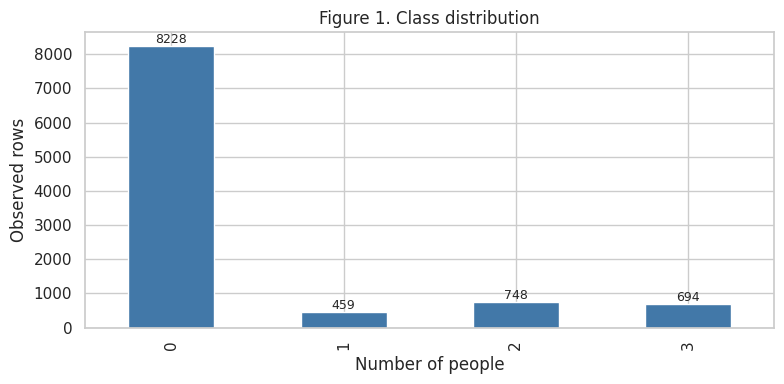

,count,percent
Room_Occupancy_Count,,
0,8228,81.23
1,459,4.53
2,748,7.38
3,694,6.85


In [ ]:
fig, ax = plt.subplots(figsize=(8,4))
counts = df[TARGET].value_counts().sort_index()
counts.plot.bar(ax=ax, color='#4278a8')
ax.set(xlabel='Number of people', ylabel='Observed rows', title='Figure 1. Class distribution')
for i, value in enumerate(counts): ax.text(i, value, str(value), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame({'count':counts, 'percent':(100*counts/counts.sum()).round(2)}))

The dataset exhibits substantial class imbalance, with approximately 81.23% of observations corresponding to an unoccupied room (class 0). Classes 1, 2 and 3 are comparatively underrepresented.

This imbalance may cause models to favour the majority class and obtain high accuracy without effectively identifying occupied-room conditions. Therefore, macro-F1 and balanced accuracy are reported alongside classification accuracy.

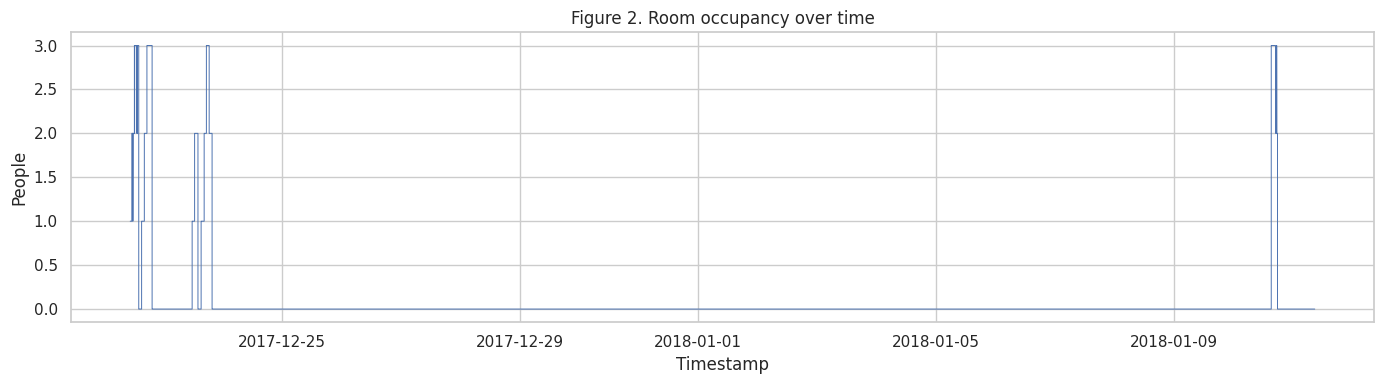

In [ ]:
fig, ax = plt.subplots(figsize=(14,4))
ax.step(df.index, df[TARGET], where='post', linewidth=0.7)
ax.set(title='Figure 2. Room occupancy over time', ylabel='People', xlabel='Timestamp')
plt.tight_layout(); plt.show()

*Figure 2: this further shows the class imbalance and the class distribution over the years.*



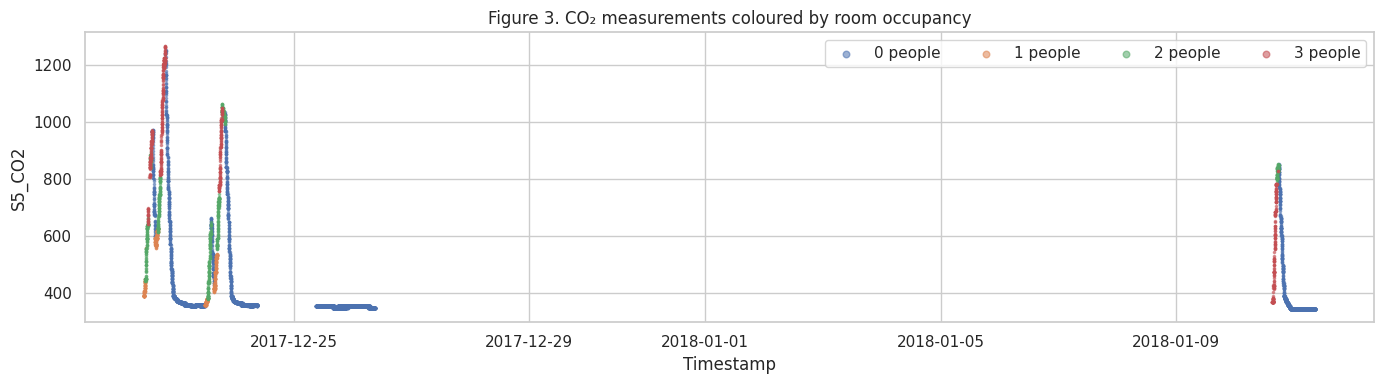

In [ ]:
co2_candidates = [c for c in df.columns if c.lower() in ['s5_co2', 'co2']]
if co2_candidates:
    co2_col = co2_candidates[0]
    fig, ax = plt.subplots(figsize=(14,4))
    classes = sorted(df[TARGET].unique())
    for label in classes:
        part = df[df[TARGET] == label]
        ax.scatter(part.index, part[co2_col], s=2.5, alpha=0.55, label=f'{label} people')
    ax.set(title='Figure 3. CO₂ measurements coloured by room occupancy', xlabel='Timestamp', ylabel=co2_col)
    ax.legend(markerscale=3, ncol=min(5,len(classes)))
    plt.tight_layout(); plt.show()
else: print('CO₂ field not found. Available columns:',df.columns.tolist())

Comparing this chart with figure 2 shows the correlation between Co2 measurements and room occupancy. (they are directly proportional to one another )

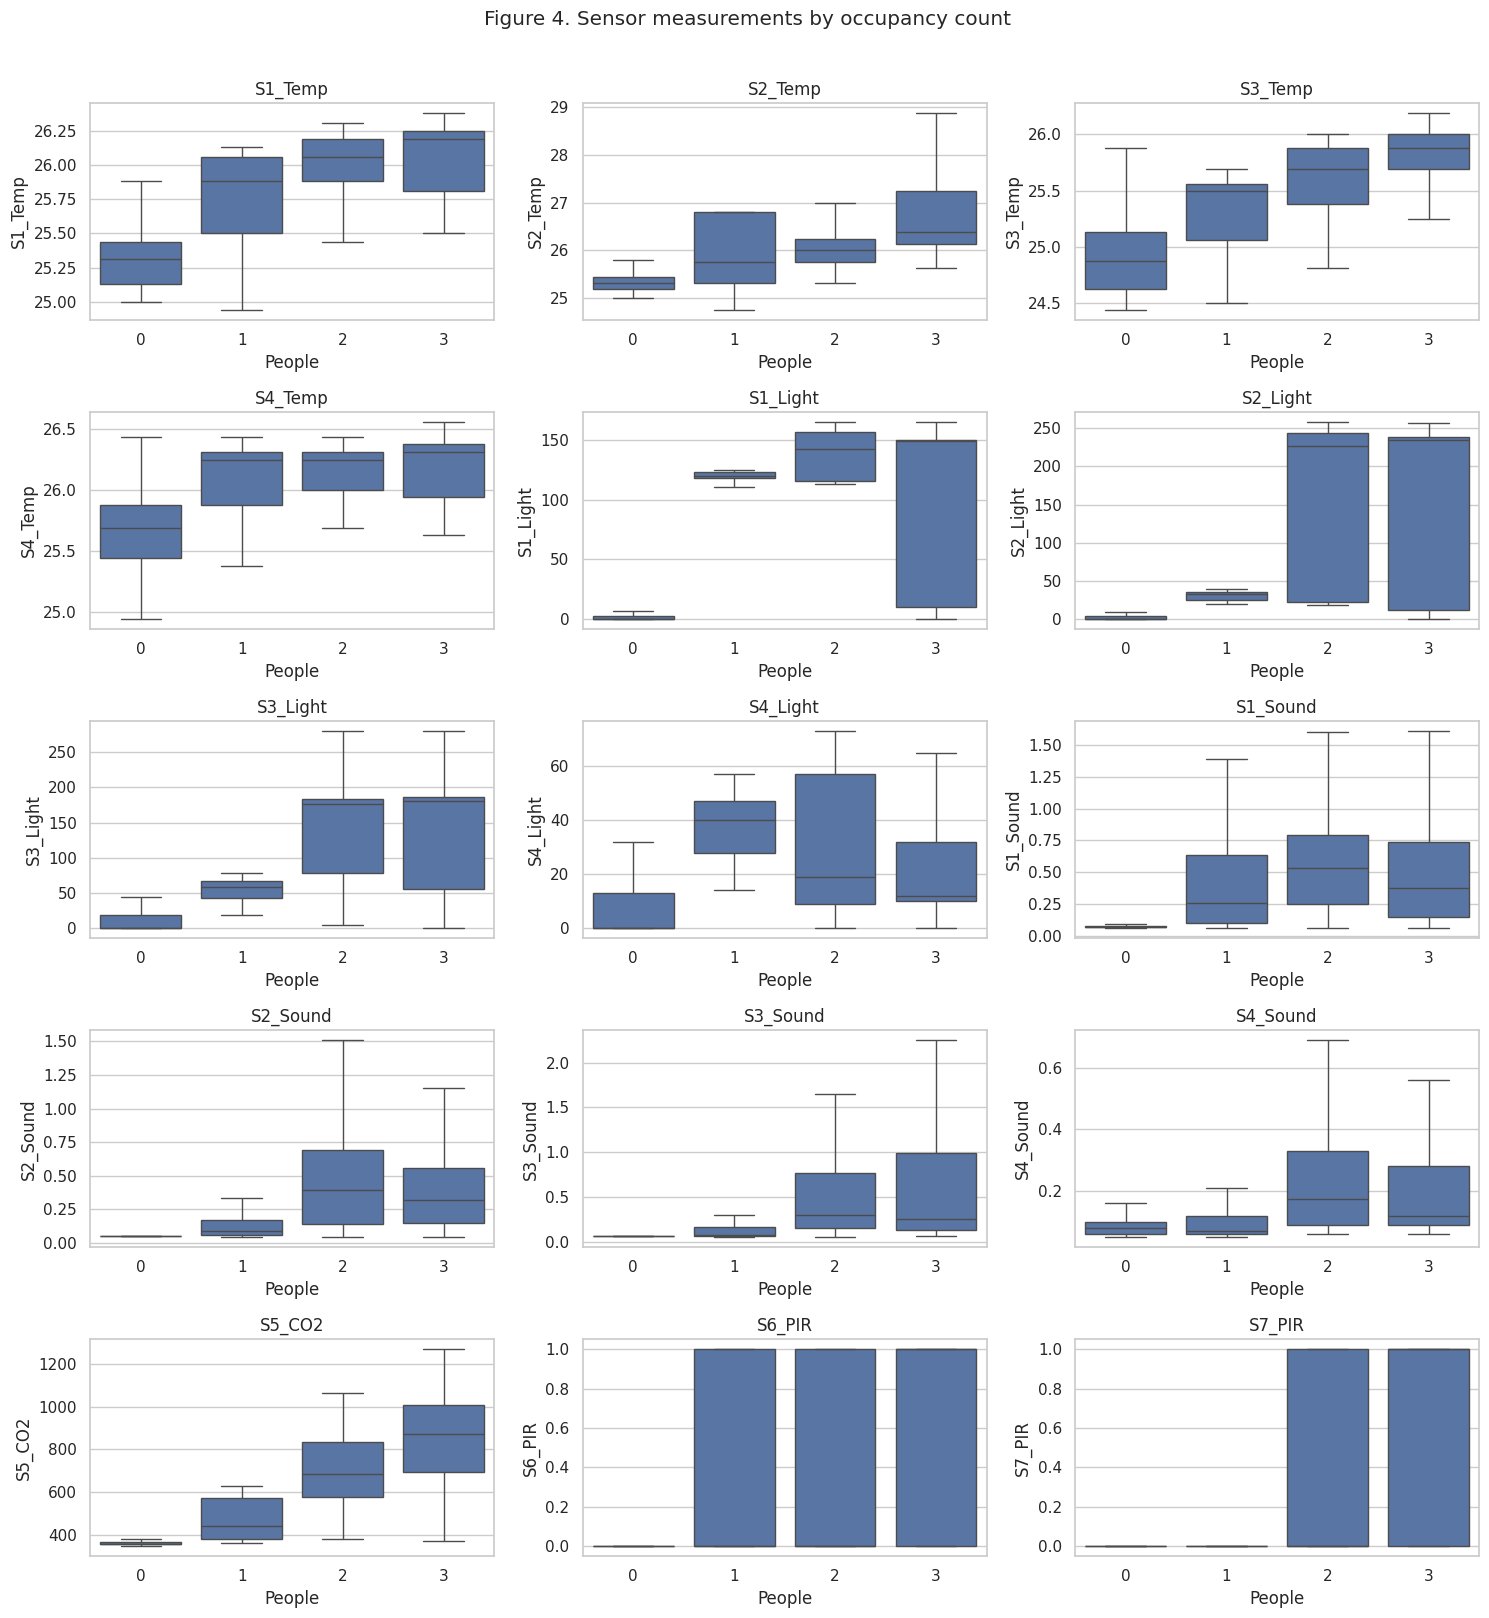

In [ ]:
sensor_cols = df.select_dtypes(include='number').columns.drop(TARGET).tolist()
# CO2 slope may be defined using future sensor points; retain for audit only, never as model input.
plot_cols = [c for c in sensor_cols if 'slope' not in c.lower()]
if plot_cols:
    ncols = 3
    nrows = (len(plot_cols)+ncols-1)//ncols
    fig, axes = plt.subplots(nrows,ncols,figsize=(15,3.2*nrows),squeeze=False)
    for ax, sensor in zip(axes.flat,plot_cols):
        sns.boxplot(data=df,x=TARGET,y=sensor,ax=ax,showfliers=False)
        ax.set_title(sensor); ax.set_xlabel('People')
    for ax in axes.flat[len(plot_cols):]: ax.axis('off')
    fig.suptitle('Figure 4. Sensor measurements by occupancy count', y=1.01)
    plt.tight_layout(); plt.show()



Sensor s5_CO2 appears to be one of the strongest class-separating sensors because its median values increase with increase in occupancy.

S3_Temp also exhibits noticeable separation between occupancy classes. Conversely, S4_Temp and S4_Sound show greater overlap, suggesting weaker individual class discrimination.

 These observations are descriptive associations and do not establish causation. Furthermore, individual sensor distributions do not necessarily determine their predictive usefulness when combined with historical measurements.

## 4. Chronological split and gap diagnostics
No shuffling. We split before fitting preprocessors or constructing windows. Check class coverage: the brief period of available data can yield splits without all occupant counts.

,split,rows,start,end,classes,missing_classes
0,train,6077,2017-12-22 10:49:41,2017-12-25 15:51:29,"{0: 4470, 1: 459, 2: 655, 3: 493}",[]
1,validation,2026,2017-12-25 15:51:59,2018-01-10 15:34:59,"{0: 2007, 3: 19}","[np.int64(1), np.int64(2)]"
2,test (sealed),2026,2018-01-10 15:35:30,2018-01-11 09:00:09,"{0: 1751, 2: 93, 3: 182}",[np.int64(1)]


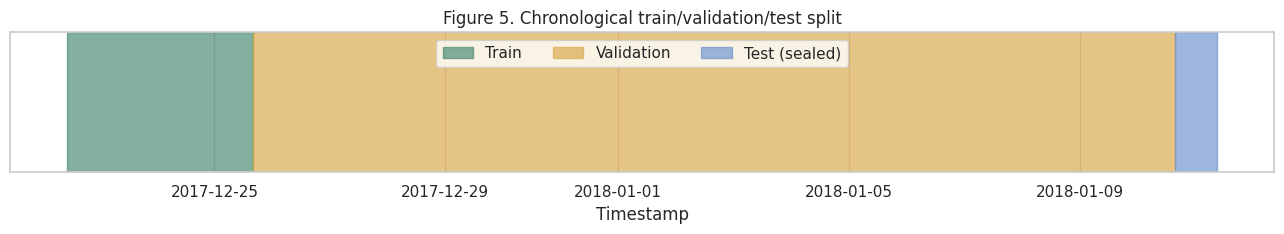

In [ ]:
n = len(df); train_end = int(n*0.6); val_end = int(n*0.8)
train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()
all_classes = sorted(df[TARGET].unique())
summary=[]
for name, part in [('train',train_df),('validation',val_df),('test (sealed)',test_df)]:
    summary.append({'split':name,'rows':len(part),'start':part.index.min(),'end':part.index.max(),
                    'classes':str(part[TARGET].value_counts().sort_index().to_dict()),
                    'missing_classes':str(sorted(set(all_classes)-set(part[TARGET].unique())))})
display(pd.DataFrame(summary))
fig, ax=plt.subplots(figsize=(13,2.5))
for name, part, color in [('Train',train_df,'#43866e'),('Validation',val_df,'#d8a645'),('Test (sealed)',test_df,'#688fcb')]:
    ax.axvspan(part.index[0],part.index[-1],color=color,alpha=.65,label=name)
ax.set_yticks([]);ax.set_xlabel('Timestamp');ax.set_title('Figure 5. Chronological train/validation/test split')
ax.legend(loc='upper center',ncol=3);plt.tight_layout();plt.show()

The initial 60/20/20 chronological split produced validation windows belonging exclusively to occupancy class 0, making multiclass evaluation unreliable.

To address this, alternative chronological boundaries were investigated using the development portion of the dataset. The revised experiment used 30% of the development data for training and the next 25% for validation, while retaining the original final 20% of the complete dataset as the sealed test partition.

This configuration produced 2,430 training observations and 2,026 validation observations. All four occupancy classes were represented in both periods. The remaining 3,647 development observations were not used in this experiment.

The revised split improves class coverage, although the limited temporal coverage and changing class proportions remain important limitations.
trianing- learning relationships and model parameters
validation- evaluating and comparing the models during development

test- final, independent evaluation.

we didn't use a random split to reduce the risk of data leakage and thus making sure the model learns from past data. An issue came up when there were no validation observations for classes 1 and 2 people. We plan to

**CO₂ slope leakage decision:** The supplied `S5_CO2_Slope` may have been calculated from measurements whose temporal support is not documented in the course handout.

Room_Occupancy_Count,0,1,2,3
row_0,,,,
2017-12-22,637,205,257,363
2017-12-23,1997,254,398,130
2017-12-24,1064,0,0,0
2017-12-25,1716,0,0,0
2017-12-26,1063,0,0,0
2018-01-10,0,0,0,19


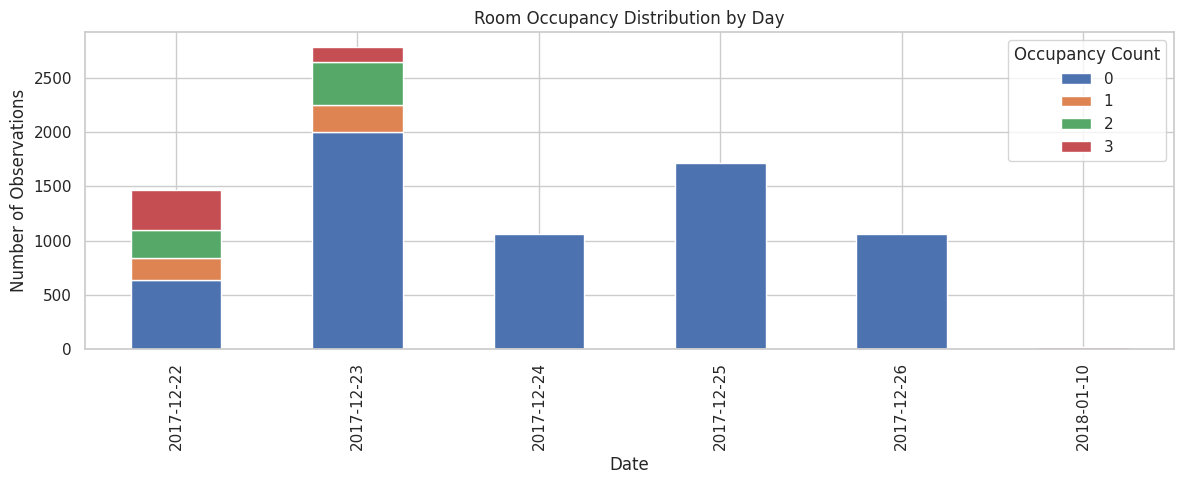

In [ ]:
# investigating where class 1 and 2 instances occur to tweak training and validation periods
# Examine occupancy distribution by day
# Use development data only; leave test untouched

development_df = pd.concat([train_df, val_df])

daily_counts = pd.crosstab(
    development_df.index.date,
    development_df[TARGET]
)

daily_counts = daily_counts.reindex(
    columns=all_classes,
    fill_value=0
)

display(daily_counts)

daily_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 5)
)

plt.title('Room Occupancy Distribution by Day')
plt.xlabel('Date')
plt.ylabel('Number of Observations')
plt.legend(title='Occupancy Count')
plt.tight_layout()
plt.show()


In [ ]:

# Screen chronological split candidates using only 80 % of the original dataset
# Valid forecast windows are connected
# The final 20% remains completely untouched

development_df = df.iloc[:int(len(df) * 0.80)].copy()
MAX_INTERVAL = pd.Timedelta(seconds=35)

def count_valid_targets(frame):
    counts = frame[TARGET].to_numpy()
    times = frame.index

    # A gap separates two recording segments
    breaks = (
        (times.to_series().diff() > MAX_INTERVAL) |
        (times.to_series().diff() <= pd.Timedelta(0))
    ).fillna(False).to_numpy()

    segment_id = np.cumsum(breaks)
    labels = []

    for i in range(LOOKBACK, len(frame) - HORIZON + 1):
        start = i - LOOKBACK
        target_pos = i + HORIZON - 1

        if segment_id[start] != segment_id[target_pos]:
            continue

        labels.append(counts[target_pos])

    return pd.Series(labels).value_counts().to_dict()


results = []

n_dev = len(development_df)

for train_fraction in np.arange(0.30, 0.71, 0.05):
    for val_fraction in [0.10, 0.15, 0.20, 0.25]:

        train_end = int(n_dev * train_fraction)
        val_end = int(n_dev * (train_fraction + val_fraction))

        if val_end > n_dev:
            continue

        candidate_train = development_df.iloc[:train_end]
        candidate_val = development_df.iloc[train_end:val_end]

        train_counts = count_valid_targets(candidate_train)
        val_counts = count_valid_targets(candidate_val)

        results.append({
            'Train % of development': round(train_fraction * 100),
            'Val % of development': round(val_fraction * 100),
            'Train end': candidate_train.index[-1],
            'Val end': candidate_val.index[-1],
            'Train classes': sorted(train_counts),
            'Val classes': sorted(val_counts),
            'Number of val classes': len(val_counts),
            'Val windows': sum(val_counts.values()),
            'Val class counts': val_counts
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ['Number of val classes', 'Val windows'],
        ascending=[False, False]
    ).head(15)
)


,Train % of development,Val % of development,Train end,Val end,Train classes,Val classes,Number of val classes,Val windows,Val class counts
11,40,25,2017-12-23 15:20:39,2017-12-24 08:50:55,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1470,"{0: 1106, 2: 179, 1: 94, 3: 91}"
3,30,25,2017-12-23 08:21:27,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1459,"{0: 905, 2: 280, 1: 183, 3: 91}"
7,35,25,2017-12-23 11:50:48,2017-12-24 05:21:04,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1443,"{0: 899, 2: 280, 1: 173, 3: 91}"
10,40,20,2017-12-23 15:20:39,2017-12-24 05:21:04,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1172,"{0: 808, 2: 179, 1: 94, 3: 91}"
2,30,20,2017-12-23 08:21:27,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1162,"{0: 608, 2: 280, 1: 183, 3: 91}"
6,35,20,2017-12-23 11:50:48,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1137,"{0: 593, 2: 280, 1: 173, 3: 91}"
9,40,15,2017-12-23 15:20:39,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,866,"{0: 502, 2: 179, 1: 94, 3: 91}"
1,30,15,2017-12-23 08:21:27,2017-12-23 18:52:01,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,862,"{0: 403, 2: 185, 1: 183, 3: 91}"
5,35,15,2017-12-23 11:50:48,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,840,"{0: 296, 2: 280, 1: 173, 3: 91}"
8,40,10,2017-12-23 15:20:39,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,569,"{0: 205, 2: 179, 1: 94, 3: 91}"


In [ ]:


# Revised chronological split using development data only
# Candidate selected for class-coverage investigation

TRAIN_FRACTION = 0.30
VAL_FRACTION = 0.25

n_dev = len(development_df)

train_end = int(n_dev * TRAIN_FRACTION)
val_end = int(n_dev * (TRAIN_FRACTION + VAL_FRACTION))

train_df = development_df.iloc[:train_end].copy()
val_df = development_df.iloc[train_end:val_end].copy()

# Keep original final 20% as sealed test data
test_df = df.iloc[int(len(df) * 0.80):].copy()

print("Training distribution:")
print(train_df[TARGET].value_counts().sort_index())

print("\nValidation distribution:")
print(val_df[TARGET].value_counts().sort_index())

print("\nTraining:", train_df.index.min(), "to", train_df.index.max())
print("Validation:", val_df.index.min(), "to", val_df.index.max())

print("\nExcluded development observations:",
      n_dev - val_end)



Training distribution:
Room_Occupancy_Count
0    1605
1     205
2     257
3     363
Name: count, dtype: int64

Validation distribution:
Room_Occupancy_Count
0    1244
1     254
2     398
3     130
Name: count, dtype: int64

Training: 2017-12-22 10:49:41 to 2017-12-23 08:21:27
Validation: 2017-12-23 08:21:58 to 2017-12-24 01:51:43

Excluded development observations: 3647


## 5. Train-only preprocessing
We retain the native frequency. Calendar features represent known-in-advance values for the **input timestamps**. A median imputer and standard scaler are fitted on training *only* and applied unchanged to validation/test.

generating imputed/scaled frames is not the same as making forecasting windows; the windows below will reject any missing or irregular timestamp jump across their entire lookback-to-target interval.

s5_co2-slope is dropped because it cannot be verified from past data only.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

safe_sensor_cols = [c for c in sensor_cols if 'slope' not in c.lower()]
assert TARGET not in safe_sensor_cols

def add_calendar(part):
    part = part.copy()
    clock = part.index.hour + part.index.minute/60 + part.index.second/3600
    day = part.index.dayofweek
    part['hour_sin'] = np.sin(2*np.pi*clock/24)
    part['hour_cos'] = np.cos(2*np.pi*clock/24)
    part['dow_sin'] = np.sin(2*np.pi*day/7)
    part['dow_cos'] = np.cos(2*np.pi*day/7)
    return part

train_df = add_calendar(train_df); val_df = add_calendar(val_df); test_df = add_calendar(test_df)
calendar_cols=['hour_sin','hour_cos','dow_sin','dow_cos']
feature_cols = safe_sensor_cols + calendar_cols
# imputation to deal with missing feature values as a safeguard. does not replace the missing time intervals
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
#Standard scaler is needed because the input features have different numerical ranges
# Reduces the dominance of larger numerical scales
#This is done only on the training set to prevent future validation statistics from defining preprocessing.
scaler = StandardScaler()
X_train_rows = scaler.fit_transform(imputer.fit_transform(train_df[feature_cols]))
X_val_rows   = scaler.transform(imputer.transform(val_df[feature_cols]))
# Sealed: transform test features if needed for final stage, but do not score them.
print('Number of lagged sensor+calendar features:',len(feature_cols))
print('Feature names:',feature_cols)
print('Train feature matrix shape:',X_train_rows.shape)

Number of lagged sensor+calendar features: 19
Feature names: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S6_PIR', 'S7_PIR', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
Train feature matrix shape: (2430, 19)


## 6. Sliding-window generation



The time series was transformed into a supervised learning problem using a lookback of 20 observations and a forecasting horizon of two observations.

The windowing procedure generated 1,636 training samples and 1,459 validation samples. Each input window has dimensions (20, 20), representing 20 historical timesteps and 20 input features.

Windows crossing intervals greater than 35 seconds were excluded to avoid combining discontinuous observations.

All four occupancy classes remain represented after window generation, allowing meaningful multiclass validation.



In [ ]:
# B3. Create supervised samples (Lab 3 style: X, y = [], [])

LOOKBACK = 20
HORIZON = 2
MAX_INTERVAL = pd.Timedelta(seconds=35) # accounting for missing time spans and gaps

def make_windows(frame, scaled_values, lookback=LOOKBACK, horizon=HORIZON):
    X, y = [], []
    persistence, timestamps = [], []
    counts = frame[TARGET].to_numpy()

    for i in range(lookback, len(frame) - horizon + 1):
        start = i - lookback
        target_pos = i + horizon - 1
        segment = frame.index[start:target_pos + 1]
        intervals = segment.to_series().diff().dropna()

        # Only real, near-contiguous observations may form a sequence.
        if not ((intervals > pd.Timedelta(0)) &
                (intervals <= MAX_INTERVAL)).all():
            continue

        past_sensors = scaled_values[start:i]
        past_counts = counts[start:i].reshape(-1, 1)
        X.append(np.column_stack([past_sensors, past_counts]))
        y.append(int(counts[target_pos]))
        persistence.append(int(counts[i - 1]))
        timestamps.append(frame.index[target_pos])

    if len(X) == 0:
        return (np.empty((0, lookback, scaled_values.shape[1] + 1), dtype='float32'),
                np.array([], dtype=int), np.array([], dtype=int), pd.DatetimeIndex([]))

    return (np.array(X, dtype='float32'), np.array(y, dtype=int),
            np.array(persistence, dtype=int), pd.DatetimeIndex(timestamps))

X_train, y_train, persist_train, t_train = make_windows(train_df, X_train_rows)
X_val, y_val, persist_val, t_val = make_windows(val_df, X_val_rows)

print('X_train shape:', X_train.shape, 'y_train shape:', y_train.shape)
print('X_val shape:  ', X_val.shape, 'y_val shape:  ', y_val.shape)
print('Training windows:', len(y_train))
print('Validation windows:', len(y_val))
print('Skipped windows (train):', max(0, len(train_df)-LOOKBACK-HORIZON+1)-len(y_train))
print('Skipped windows (val):', max(0, len(val_df)-LOOKBACK-HORIZON+1)-len(y_val))

assert len(y_train) > 0 and len(y_val) > 0, (
    'No valid windows. Check the timestamp counts and MAX_INTERVAL (do not ignore large gaps).')
assert t_train.max() < t_val.min(), 'Train/validation target overlap detected'
print('First training X window shape:', X_train[0].shape)
print('Class counts in training windows:', dict(zip(*np.unique(y_train, return_counts=True))))
print('Class counts in validation windows:', dict(zip(*np.unique(y_val, return_counts=True))))


X_train shape: (1636, 20, 20) y_train shape: (1636,)
X_val shape:   (1459, 20, 20) y_val shape:   (1459,)
Training windows: 1636
Validation windows: 1459
Skipped windows (train): 773
Skipped windows (val): 546
First training X window shape: (20, 20)
Class counts in training windows: {np.int64(0): np.int64(1131), np.int64(1): np.int64(140), np.int64(2): np.int64(148), np.int64(3): np.int64(217)}
Class counts in validation windows: {np.int64(0): np.int64(905), np.int64(1): np.int64(183), np.int64(2): np.int64(280), np.int64(3): np.int64(91)}


In [ ]:

# Verify the actual classes available for model evaluation

print("Training window class counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nValidation window class counts:")
print(pd.Series(y_val).value_counts().sort_index())

print("\nClasses in training:",
      np.unique(y_train))

print("Classes in validation:",
      np.unique(y_val))

assert set(all_classes).issubset(set(y_train)), \
    "Some classes are missing from training windows"

assert set(all_classes).issubset(set(y_val)), \
    "Some classes are missing from validation windows"

print("\nAll four occupancy classes are represented.")


Training window class counts:
0    1131
1     140
2     148
3     217
Name: count, dtype: int64

Validation window class counts:
0    905
1    183
2    280
3     91
Name: count, dtype: int64

Classes in training: [0 1 2 3]
Classes in validation: [0 1 2 3]

All four occupancy classes are represented.


## 7. Traditional baselines


Three traditional predictors were evaluated: majority-class prediction, persistence and Random Forest.

The majority baseline achieved 62.03% accuracy and macro-F1 of 0.1914, demonstrating the limitations of always predicting the most frequent training class.

The persistence baseline achieved 99.45% accuracy and macro-F1 of 0.9899. This indicates strong short-term temporal stability in room occupancy: the most recently observed count usually remains unchanged over the approximately one-minute prediction horizon.

Random Forest achieved 90.95% accuracy and macro-F1 of 0.8191. Although it substantially outperformed the majority baseline, it did not outperform persistence. we used 150 trees, each with a leaf size of 3 and a max depth of 12


 Majority


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Majority,0.6203,0.1914,0.25,0,0.0


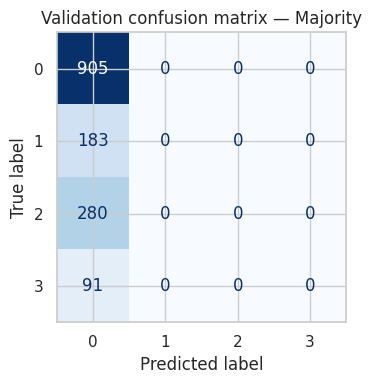


 Persistence


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Persistence,0.9945,0.9899,0.9894,0,0.0


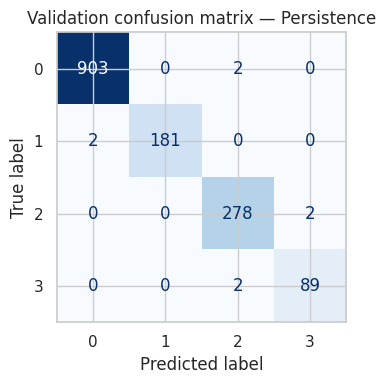


 Random forest


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Random forest,0.9095,0.8191,0.8701,150,0.8914


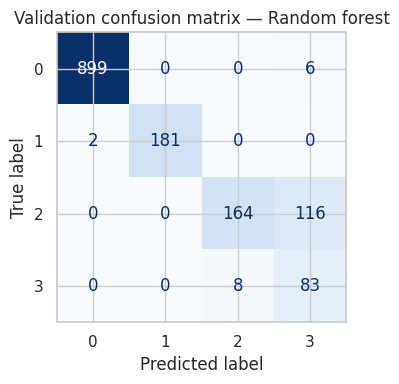

{'Model': 'Random forest',
 'Accuracy': 0.9095270733379027,
 'Macro F1': 0.8191375858205453,
 'Balanced accuracy': np.float64(0.870060850449855),
 'Parameters / trees': 150,
 'Train seconds': 0.891410292000046}

In [ ]:
from sklearn.metrics import accuracy_score,f1_score,balanced_accuracy_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from collections import Counter

results=[]
def evaluate_validation(name,pred,fit_seconds=0.0,params=0):
    row={'Model':name,'Accuracy':accuracy_score(y_val,pred),
         'Macro F1':f1_score(y_val,pred,labels=all_classes,average='macro',zero_division=0),
         'Balanced accuracy':balanced_accuracy_score(y_val,pred),
         'Parameters / trees':params,'Train seconds':fit_seconds}
    results.append(row)
    print('\n',name);display(pd.DataFrame([row]).round(4))
    cm=confusion_matrix(y_val,pred,labels=all_classes)
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(cm,display_labels=all_classes).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(f'Validation confusion matrix — {name}')
    plt.tight_layout();plt.show()
    return row

majority_label=Counter(y_train).most_common(1)[0][0]
majority_val=np.full(len(y_val),majority_label,dtype=int)
evaluate_validation('Majority',majority_val)
evaluate_validation('Persistence',persist_val)

start=time.perf_counter()
#initializing the random forest classifier
forest=RandomForestClassifier(n_estimators=150,max_depth=12,min_samples_leaf=3,
                             random_state=SEED,n_jobs=-1)
forest.fit(X_train.reshape(len(X_train),-1),y_train)
forest_time=time.perf_counter()-start
rf_val=forest.predict(X_val.reshape(len(X_val),-1))
evaluate_validation('Random forest',rf_val,forest_time,params=forest.n_estimators)

In [ ]:

# Evaluate persistence specifically at occupancy transitions

#identifies windows where the true future count differs from the last observed count
transition_mask = y_val != persist_val

print("Total validation windows:", len(y_val))
print("Occupancy transitions:", transition_mask.sum())
print("Stable occupancy windows:", (~transition_mask).sum())

print("Transition rate (%):",
      round(100 * transition_mask.mean(), 2))

print("Persistence accuracy (%):",
      round(100 * accuracy_score(y_val, persist_val), 2))


Total validation windows: 1459
Occupancy transitions: 8
Stable occupancy windows: 1451
Transition rate (%): 0.55
Persistence accuracy (%): 99.45


In [ ]:

# Additional analysis: temporal persistence

same_count = (y_val == persist_val)
changed_count = ~same_count

print("Stable occupancy predictions:", same_count.sum())
print("Occupancy changes:", changed_count.sum())

print("Percentage with unchanged occupancy:",
      round(same_count.mean() * 100, 2), "%")

print("Persistence errors:",
      np.sum(y_val != persist_val))

# Class-specific persistence performance
from sklearn.metrics import classification_report

print("\nPersistence classification report:")
print(classification_report(
    y_val,
    persist_val,
    labels=all_classes,
    zero_division=0
))


Stable occupancy predictions: 1451
Occupancy changes: 8
Percentage with unchanged occupancy: 99.45 %
Persistence errors: 8

Persistence classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       905
           1       1.00      0.99      0.99       183
           2       0.99      0.99      0.99       280
           3       0.98      0.98      0.98        91

    accuracy                           0.99      1459
   macro avg       0.99      0.99      0.99      1459
weighted avg       0.99      0.99      0.99      1459



This analysis reaffirms that the persistence baselien is exceptionally strong. This could be because occupancy tends to remain constant over short periods of time which exhibits short-term temporal persistence

## 8. MLP & CNN Results

### 8a. MLP Results
The MLP achieved 86.84% validation accuracy and macro-F1 of 0.7602, using 12,964 trainable parameters.

The model flattened each historical window into a feature vector and learned nonlinear relationships using fully connected layers. Training loss decreased during optimization, indicating successful fitting of the training objective.

However, validation performance remained below the persistence baseline. This suggests that the additional model complexity did not provide an advantage under the current short forecasting horizon and dataset conditions.




###8b. CNN Results

The initial CNN achieved 88.62% validation accuracy and macro-F1 of 0.7882, using 5,188 trainable parameters.

Unlike the MLP, the CNN used one-dimensional convolutional filters to capture local temporal patterns in the sensor measurements.

The CNN achieved slightly higher macro-F1 than the MLP while using fewer trainable parameters. Nevertheless, both neural models performed below the persistence baseline.

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,964 (50.64 KB)

 Trainable params: 12,964 (50.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - accuracy: 0.4811 - loss: 1.2493 - val_accuracy: 0.7587 - val_loss: 0.7197
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8631 - loss: 0.3823 - val_accuracy: 0.8506 - val_loss: 0.4406
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8936 - loss: 0.2818 - val_accuracy: 0.8410 - val_loss: 0.4728
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9175 - loss: 0.2133 - val_accuracy: 0.8595 - val_loss: 0.4176
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9432 - loss: 0.1678 - val_accuracy: 0.8670 - val_loss: 0.4127
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9468 - loss: 0.1401 - val_accuracy: 0.8588 - val_loss: 0.4341
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9615 - loss: 0.1189 - val_accuracy: 0.8684 - val_loss: 0.4117
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9694 - loss: 0.0965 - val_accuracy: 0.8588 - 

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,MLP,0.8684,0.7602,0.8424,12964,7.9979


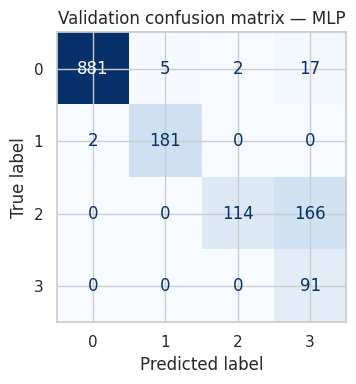

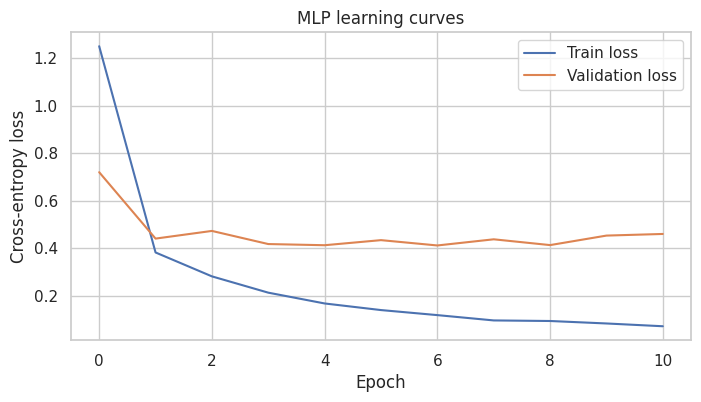

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 20, 32)         │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 10, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,188 (20.27 KB)

 Trainable params: 5,188 (20.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 610ms/step - accuracy: 0.6950 - loss: 1.2072 - val_accuracy: 0.6470 - val_loss: 1.0772
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8826 - loss: 0.7179 - val_accuracy: 0.6717 - val_loss: 0.7822
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8606 - loss: 0.4694 - val_accuracy: 0.6813 - val_loss: 0.6241
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8576 - loss: 0.3466 - val_accuracy: 0.7279 - val_loss: 0.5535
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8888 - loss: 0.2785 - val_accuracy: 0.7786 - val_loss: 0.5089
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9071 - loss: 0.2324 - val_accuracy: 0.7875 - val_loss: 0.4738
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9352 - loss: 0.1984 - val_accuracy: 0.7910 - val_loss: 0.4454
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9444 - loss: 0.1722 - val_accuracy: 0.8204 -

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,CNN,0.8862,0.7882,0.8406,5188,16.8224


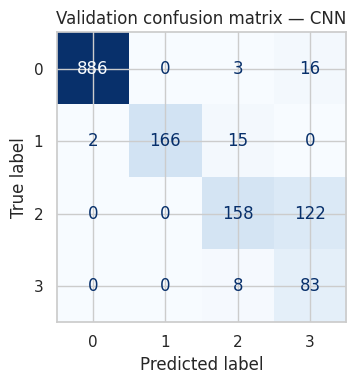

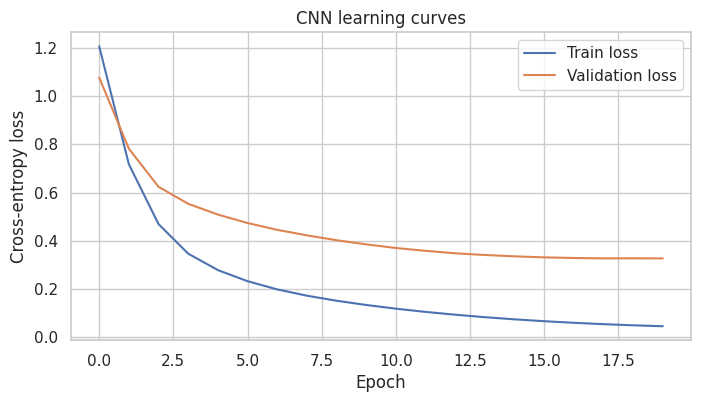

In [ ]:
# B5. MLP and CNN: Sequential API (adapted from Lab 3)
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Flatten, Dropout, Conv1D, MaxPooling1D
from tensorflow.keras.layers import GlobalAveragePooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)
classes = np.array(all_classes)
class_to_idx = {value: i for i, value in enumerate(classes)}
y_train_idx = np.array([class_to_idx[value] for value in y_train])
y_val_idx = np.array([class_to_idx[value] for value in y_val])
n_classes = len(classes)

EPOCHS = 20
BATCH_SIZE = 128

def build_mlp(units=32, lr=0.001):
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        Flatten(),
        Dense(units, activation='relu'),
        Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_cnn(filters=32, kernel_size=3, lr=0.001):
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        Conv1D(filters=filters, kernel_size=kernel_size,
               padding='causal', activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=filters, kernel_size=kernel_size,
               padding='causal', activation='relu'),
        GlobalAveragePooling1D(),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def fit_and_predict(model, epochs=EPOCHS):
    early_stop = EarlyStopping(monitor='val_loss', patience=4,
                               restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train_idx,
                        validation_data=(X_val, y_val_idx),
                        epochs=epochs, batch_size=BATCH_SIZE,
                        shuffle=False, callbacks=[early_stop], verbose=1)
    elapsed = time.perf_counter() - start
    prediction = model.predict(X_val, verbose=0).argmax(axis=1)
    prediction = classes[prediction]
    return history, prediction, elapsed

models = {}
histories = {}
if RUN_DEEP_MODELS:
    for model_name, builder in [('MLP', build_mlp), ('CNN', build_cnn)]:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = builder()
        model.summary()
        history, pred, seconds = fit_and_predict(model)
        models[model_name] = model
        histories[model_name] = history
        evaluate_validation(model_name, pred, seconds, model.count_params())

        plt.figure(figsize=(8, 4))
        plt.plot(history.history['loss'], label='Train loss')
        plt.plot(history.history['val_loss'], label='Validation loss')
        plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss')
        plt.title(model_name + ' learning curves')
        plt.legend(); plt.show()
else:
    print('Neural models skipped. Change RUN_DEEP_MODELS to True to run.')


Training lods show increasing training accuracy and decreasing training loss which is evidence of optimization to the training objective.

## 9. Small grid search — Grid-search optimization

A grid search was conducted using two filter counts (16 and 32) and two learning rates (0.01 and 0.001), giving four CNN configurations which we evaluated using validation macro-F1 because our occupancy classes are imbalanced. The best configuration used 16 filters and a learning rate of 0.01, achieving a macro-F1 score of 0.8284. This improved upon our initial CNN score of 0.7882, while also reducing the number of trainable parameters.


This improved upon the original CNN's macro-F1 of 0.7882. The selected model also required fewer parameters (1,828), indicating that greater architectural complexity was not necessary for the best CNN result in this experiment.




Input (20 timestamps x 20 features )

Conv1D - 32 filters, kernel size 3

Maxpooling1D - pool size 2 ( reduces sequence length from 20 to 10 )

Conv1D - 32 filters, kernel size 3

GlobalAveragePooling 1D (summarizes learned feature maps )

Dense - 4 , softmax

Total trainable parameters 5188

This is smaller than the MLP because convolution layers reuse filter weights instead of learning separate dense connections.

Epoch 1/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 11s 488ms/step - accuracy: 0.6290 - loss: 0.9879 - val_accuracy: 0.8026 - val_loss: 0.5514
Epoch 2/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7787 - loss: 0.4003 - val_accuracy: 0.7800 - val_loss: 0.4344
Epoch 3/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.8875 - loss: 0.2451 - val_accuracy: 0.7834 - val_loss: 0.4335
Epoch 4/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9059 - loss: 0.1728 - val_accuracy: 0.8643 - val_loss: 0.3066
Epoch 5/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9407 - loss: 0.1261 - val_accuracy: 0.8074 - val_loss: 0.3997
Epoch 6/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9456 - loss: 0.1151 - val_accuracy: 0.9191 - val_loss: 0.2451
Epoch 7/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.9432 - loss: 0.1308 - val_accuracy: 0.7464 - val_loss: 0.6286
Epoch 8/15
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9083 - loss: 0.1865 - val_accuracy: 0.8568 -

,filters,learning_rate,validation_macro_f1,epochs,parameters,training_seconds
0,16,0.010,0.8284,10,1828,12.7287
3,32,0.001,0.7976,15,5188,7.0936
2,32,0.010,0.6965,8,5188,5.6124
1,16,0.001,0.6575,15,1828,6.1507


Best grid-search configuration: {'filters': 16, 'lr': 0.01}

 CNN (grid selected)


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,CNN (grid selected),0.9191,0.8284,0.8566,1828,12.7287


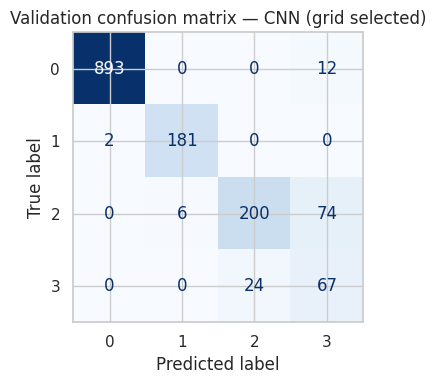

In [ ]:
# B6. Small grid search — itertools.product
from itertools import product

grid = {'filters': [16, 32], 'lr': [0.01, 0.001]}
grid_results = []
best_grid_model = None
best_grid_score = -1
best_grid_config = None

if RUN_DEEP_MODELS and RUN_GRID_SEARCH:
    for filters, lr in product(grid['filters'], grid['lr']):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = build_cnn(filters=filters, lr=lr)
        history, pred, elapsed = fit_and_predict(model, epochs=15)
        macro_f1 = f1_score(y_val, pred, labels=all_classes,
                            average='macro', zero_division=0)
        grid_results.append({'filters': filters, 'learning_rate': lr,
                             'validation_macro_f1': macro_f1,
                             'epochs': len(history.history['loss']),
                             'parameters': model.count_params(),
                             'training_seconds': elapsed})
        if macro_f1 > best_grid_score:
            best_grid_score = macro_f1
            best_grid_config = {'filters': filters, 'lr': lr}
            best_grid_model = model

    grid_table = pd.DataFrame(grid_results).sort_values(
        'validation_macro_f1', ascending=False)
    display(grid_table.round(4))
    print('Best grid-search configuration:', best_grid_config)
    best_pred = classes[best_grid_model.predict(X_val, verbose=0).argmax(axis=1)]
    selected = grid_table.iloc[0]
    evaluate_validation('CNN (grid selected)', best_pred,
                        float(selected['training_seconds']), best_grid_model.count_params())
else:
    print('Grid search skipped by configuration.')


Using the same training and validation windows, the MLp flattens the time-series input and learns relationships through fully connected layers , while the CNN uses convolutional filters to identify local temporal patterns.



## 9b. Recurrent models: SimpleRNN, LSTM and GRU

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 20, 64)         │         5,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,676 (33.89 KB)

 Trainable params: 8,676 (33.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 9s 330ms/step - accuracy: 0.0935 - loss: 1.5744 - val_accuracy: 0.6326 - val_loss: 0.9542
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8753 - loss: 0.4757 - val_accuracy: 0.7238 - val_loss: 0.5855
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9230 - loss: 0.2821 - val_accuracy: 0.7498 - val_loss: 0.4994
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9419 - loss: 0.2207 - val_accuracy: 0.7533 - val_loss: 0.4758
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9474 - loss: 0.1834 - val_accuracy: 0.7574 - val_loss: 0.4476
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9505 - loss: 0.1592 - val_accuracy: 0.7656 - val_loss: 0.4327
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9603 - loss: 0.1409 - val_accuracy: 0.7937 - val_loss: 0.4044
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9743 - loss: 0.1257 - val_accuracy: 0.8074 - 

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,RNN,0.8225,0.6671,0.7226,8676,12.3426


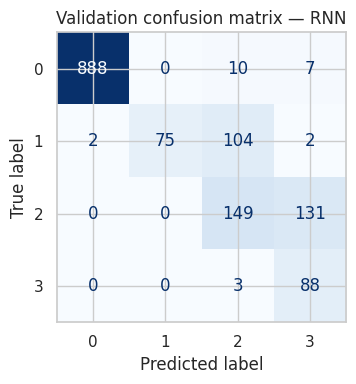

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 20, 64)         │        21,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,308 (134.02 KB)

 Trainable params: 34,308 (134.02 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 41ms/step - accuracy: 0.6137 - loss: 1.1891 - val_accuracy: 0.7231 - val_loss: 0.9370
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.8466 - loss: 0.5360 - val_accuracy: 0.7793 - val_loss: 0.5833
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9413 - loss: 0.3335 - val_accuracy: 0.8047 - val_loss: 0.4410
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9584 - loss: 0.2270 - val_accuracy: 0.8300 - val_loss: 0.3887
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9768 - loss: 0.1616 - val_accuracy: 0.8533 - val_loss: 0.3488
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9896 - loss: 0.1150 - val_accuracy: 0.8595 - val_loss: 0.3512
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9890 - loss: 0.0894 - val_accuracy: 0.8828 - val_loss: 0.2754
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9780 - loss: 0.0940 - val_accuracy: 0.8314 - v

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,LSTM,0.8917,0.7944,0.8204,34308,12.9633


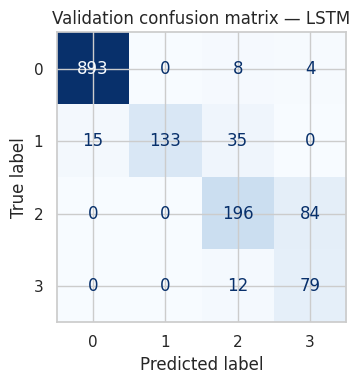

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 20, 64)         │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 26,052 (101.77 KB)

 Trainable params: 26,052 (101.77 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.5116 - loss: 1.2122 - val_accuracy: 0.7553 - val_loss: 0.9464
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9358 - loss: 0.5120 - val_accuracy: 0.7347 - val_loss: 0.5958
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9432 - loss: 0.3352 - val_accuracy: 0.7341 - val_loss: 0.4845
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9358 - loss: 0.2517 - val_accuracy: 0.7560 - val_loss: 0.4453
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9383 - loss: 0.1977 - val_accuracy: 0.7724 - val_loss: 0.4197
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9523 - loss: 0.1643 - val_accuracy: 0.7855 - val_loss: 0.3956
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.9829 - loss: 0.1378 - val_accuracy: 0.8053 - val_loss: 0.3790
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9902 - loss: 0.1155 - val_accuracy: 0.8273 - v

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,GRU,0.83,0.6813,0.7712,26052,5.2289


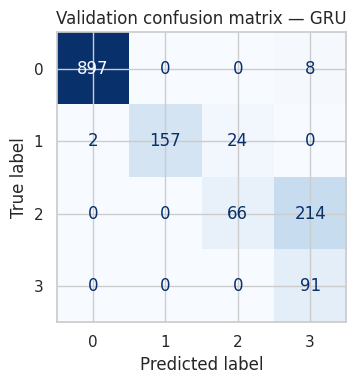

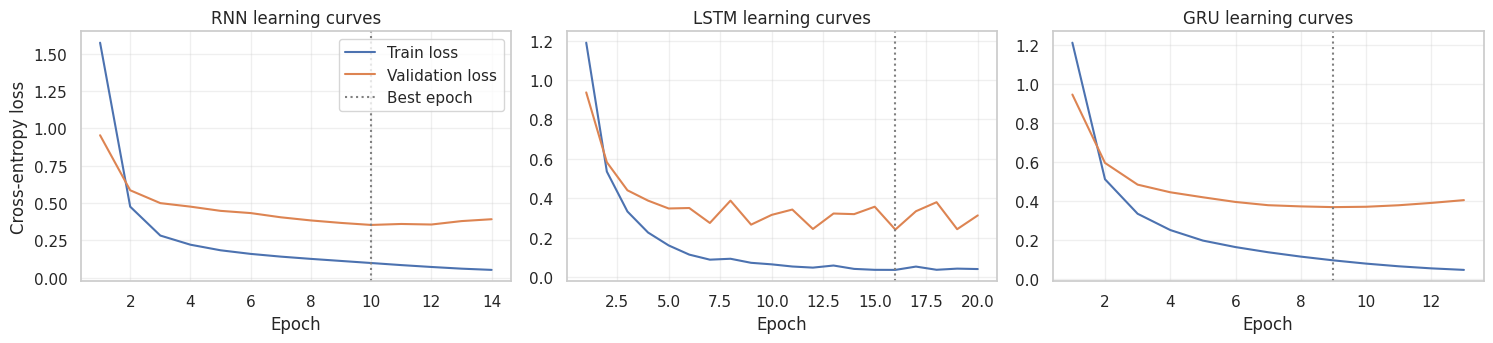

In [ ]:
# B7. Stacked SimpleRNN, LSTM and GRU (architecture from Lab 6; same windows, callbacks and metrics as MLP / CNN)
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU

def build_recurrent(cell, units=(64, 32), lr=0.001, clip=1.0):
    """Two stacked recurrent layers followed by a softmax over the occupancy classes."""
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        cell(units[0], return_sequences=True),   # passes the full sequence to the next layer
        cell(units[1]),                          # returns only the last hidden state
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr, clipnorm=clip),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_rnn(**kw):  return build_recurrent(SimpleRNN, **kw)
def build_lstm(**kw): return build_recurrent(LSTM, **kw)
def build_gru(**kw):  return build_recurrent(GRU, **kw)

recurrent_histories = {}
if RUN_DEEP_MODELS:
    for model_name, builder in [('RNN', build_rnn), ('LSTM', build_lstm), ('GRU', build_gru)]:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = builder()
        model.summary()
        history, pred, seconds = fit_and_predict(model)
        models[model_name] = model
        histories[model_name] = history
        recurrent_histories[model_name] = history.history
        evaluate_validation(model_name, pred, seconds, model.count_params())

    # Training vs validation loss for the three recurrent models (check for over/underfitting)
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
    for ax, (model_name, h) in zip(axes, recurrent_histories.items()):
        epochs = np.arange(1, len(h['loss']) + 1)
        ax.plot(epochs, h['loss'], label='Train loss')
        ax.plot(epochs, h['val_loss'], label='Validation loss')
        ax.axvline(np.argmin(h['val_loss']) + 1, color='grey', ls=':', label='Best epoch')
        ax.set_title(model_name + ' learning curves'); ax.set_xlabel('Epoch'); ax.grid(alpha=0.3)
    axes[0].set_ylabel('Cross-entropy loss'); axes[0].legend()
    plt.tight_layout(); plt.show()
else:
    print('Neural models skipped. Change RUN_DEEP_MODELS to True to run.')

###**SimpleRNN hyperparameter tuning**

This search tunes the existing stacked SimpleRNN architecture. It tests two layer-width settings, two dropout settings and two learning rates (8 combinations). LSTM and GRU are not modified by this cell.

In [ ]:
# B7a. SimpleRNN HPO: 8 trials, validation macro-F1 objective
from itertools import product
from tensorflow.keras.layers import SimpleRNN, Dropout

RNN_SEARCH = {
    'units': [(32, 16), (64, 32)],
    'dropout': [0.0, 0.2],
    'lr': [0.001, 0.0005]
}
rnn_trials = []
best_rnn_model, best_rnn_config, best_rnn_key = None, None, None
best_rnn_seconds = None

def build_tunable_rnn(units=(32, 16), dropout=0.2, lr=0.001, clip=1.0):
    # Keep the existing two-layer SimpleRNN structure; tune width, dropout and learning rate.
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        SimpleRNN(units[0], return_sequences=True),
        Dropout(dropout),
        SimpleRNN(units[1]),
        Dropout(dropout),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(
        optimizer=Adam(learning_rate=lr, clipnorm=clip),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

if RUN_DEEP_MODELS and RUN_GRID_SEARCH:
    for units, dropout, lr in product(
        RNN_SEARCH['units'], RNN_SEARCH['dropout'], RNN_SEARCH['lr']
    ):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        config = {'units': units, 'dropout': dropout, 'lr': lr}
        trial_model = build_tunable_rnn(**config)
        history, pred, elapsed = fit_and_predict(trial_model, epochs=20)
        macro_f1 = f1_score(
            y_val, pred, labels=all_classes, average='macro', zero_division=0
        )
        params = trial_model.count_params()
        rnn_trials.append({
            'trial': len(rnn_trials) + 1,
            'units': str(units),
            'dropout': dropout,
            'learning_rate': lr,
            'validation_macro_f1': float(macro_f1),
            'validation_accuracy': float(accuracy_score(y_val, pred)),
            'epochs': len(history.history['loss']),
            'parameters': int(params),
            'training_seconds': float(elapsed)
        })
        key = (float(macro_f1), -int(params))
        if best_rnn_key is None or key > best_rnn_key:
            best_rnn_key = key
            best_rnn_config = config.copy()
            best_rnn_model = trial_model
            best_rnn_seconds = float(elapsed)

    rnn_trials_df = pd.DataFrame(rnn_trials).sort_values(
        ['validation_macro_f1', 'parameters'], ascending=[False, True]
    ).reset_index(drop=True)
    display(rnn_trials_df.round(5))
    print('Best SimpleRNN configuration:', best_rnn_config)
    print('Best SimpleRNN validation macro-F1:', round(best_rnn_key[0], 5))

    # Plot all SimpleRNN trials so the selection is visible and auditable.
    plot_rnn = rnn_trials_df.sort_values('validation_macro_f1')
    plt.figure(figsize=(9, 4.5))
    labels = [
        f"units={r.units}, drop={r.dropout}, lr={r.learning_rate}"
        for r in plot_rnn.itertuples()
    ]
    plt.barh(labels, plot_rnn['validation_macro_f1'])
    plt.xlabel('Validation macro-F1')
    plt.title('SimpleRNN hyperparameter trials')
    plt.xlim(0, 1)
    plt.grid(axis='x', alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print('SimpleRNN HPO skipped: set RUN_DEEP_MODELS and RUN_GRID_SEARCH to True.')


## 9c. Temporal Convolutional Network (TCN)

A TCN is a stack of **causal, dilated 1D convolutions** with residual connections.

* **Causal**: the output at step *t* only uses inputs at steps ≤ *t* (`padding='causal'`), so no future
  information inside the window can leak into the prediction.
* **Dilated**: each residual block skips inputs with dilation 1, 2, 4, 8, ... so the receptive field
  grows exponentially with depth while the parameter count stays small.
* **Residual**: each block adds its input back to its output (1×1 conv when channel counts differ),
  which keeps deeper stacks stable to train.

Each residual block has two causal convolutions, so the receptive field is
**RF = 1 + 2·(k − 1)·Σ dᵢ**. We require **RF ≥ LOOKBACK (20)** so the model can use the full window.
The last timestep of the final block feeds a softmax over the 4 occupancy classes, same output
as MLP/CNN/RNN. Same windows, split, loss, callbacks and metrics as every other model.
"""

In [ ]:
# B8. TCN builder (Keras functional API)
import tensorflow as tf
from tensorflow.keras import Model, Input
from tensorflow.keras.layers import Dense, Flatten, Conv1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Add, Activation, LayerNormalization, SpatialDropout1D, Cropping1D
from tensorflow.keras.callbacks import EarlyStopping

# --- Safety setup: recreate the shared objects from B5 if that cell did not run ---
if 'n_classes' not in globals():
    print('B5 objects missing -> recreating them here')
    classes = np.array(all_classes)
    class_to_idx = {value: i for i, value in enumerate(classes)}
    y_train_idx = np.array([class_to_idx[v] for v in y_train])
    y_val_idx = np.array([class_to_idx[v] for v in y_val])
    n_classes = len(classes)
    EPOCHS, BATCH_SIZE = 20, 128
    models, histories = {}, {}

if 'fit_and_predict' not in globals():
    def fit_and_predict(model, epochs=EPOCHS):
        early_stop = EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
        start = time.perf_counter()
        history = model.fit(X_train, y_train_idx, validation_data=(X_val, y_val_idx),
                            epochs=epochs, batch_size=BATCH_SIZE, shuffle=False,
                            callbacks=[early_stop], verbose=1)
        elapsed = time.perf_counter() - start
        prediction = classes[model.predict(X_val, verbose=0).argmax(axis=1)]
        return history, prediction, elapsed

missing = [name for name in ['X_train', 'X_val', 'y_train', 'y_val', 'all_classes',
                             'evaluate_validation', 'results'] if name not in globals()]
assert not missing, f'Run the earlier cells first (sections 4-7). Missing: {missing}'

def tcn_receptive_field(kernel_size, dilations, convs_per_block=2):
    """Number of past timesteps the last output can see."""
    return 1 + convs_per_block * (kernel_size - 1) * sum(dilations)

def tcn_residual_block(x, filters, kernel_size, dilation, dropout, name):
    shortcut = x
    for j in (1, 2):
        x = Conv1D(filters, kernel_size, padding='causal', dilation_rate=dilation,
                   name=f'{name}_conv{j}')(x)
        x = LayerNormalization(name=f'{name}_norm{j}')(x)
        x = Activation('relu', name=f'{name}_relu{j}')(x)
        x = SpatialDropout1D(dropout, name=f'{name}_drop{j}')(x)
    if shortcut.shape[-1] != filters:                     # match channels for the skip connection
        shortcut = Conv1D(filters, 1, padding='same', name=f'{name}_skip')(shortcut)
    x = Add(name=f'{name}_add')([x, shortcut])
    return Activation('relu', name=f'{name}_out')(x)

def build_tcn(filters=32, kernel_size=3, dilations=(1, 2, 4), dropout=0.1, lr=0.001):
    inputs = Input(shape=X_train.shape[1:], name='window')        # (LOOKBACK, n_features)
    x = inputs
    for d in dilations:
        x = tcn_residual_block(x, filters, kernel_size, d, dropout, name=f'tcn_d{d}')
    x = Activation('linear', name='tcn_sequence')(x)               # full causal feature sequence
    last = Cropping1D((X_train.shape[1] - 1, 0), name='last_step')(x)  # keep only the latest step
    last = Flatten(name='last_step_flat')(last)
    outputs = Dense(n_classes, activation='softmax', name='occupancy')(last)
    model = Model(inputs, outputs, name='TCN')
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def inference_ms_per_window(model, X, repeats=3):
    """Median wall-clock prediction time per window (ms), after one warm-up call."""
    model.predict(X[:BATCH_SIZE], verbose=0)
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter(); model.predict(X, batch_size=BATCH_SIZE, verbose=0)
        times.append(time.perf_counter() - t0)
    return 1000 * float(np.median(times)) / len(X)

TCN_DEFAULT = dict(filters=32, kernel_size=3, dilations=(1, 2, 4), dropout=0.1, lr=0.001)
print('Default TCN receptive field:',
      tcn_receptive_field(TCN_DEFAULT['kernel_size'], TCN_DEFAULT['dilations']),
      'timesteps | LOOKBACK =', LOOKBACK)

Default TCN receptive field: 29 timesteps | LOOKBACK = 20


In [ ]:
# Causality check: changing the LAST input step must not change any earlier TCN output step.
tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
_probe = build_tcn(**TCN_DEFAULT)
_seq = Model(_probe.input, _probe.get_layer('tcn_sequence').output)

x_a = X_val[:1].copy()
x_b = x_a.copy(); x_b[:, -1, :] += 5.0                   # large perturbation at the newest timestep
out_a = _seq(x_a, training=False).numpy(); out_b = _seq(x_b, training=False).numpy()

earlier_diff = np.abs(out_a[:, :-1, :] - out_b[:, :-1, :]).max()
last_diff = np.abs(out_a[:, -1, :] - out_b[:, -1, :]).max()
print(f'Max change at earlier steps: {earlier_diff:.2e} (should be ~0)')
print(f'Max change at last step:     {last_diff:.2e} (should be > 0)')
assert earlier_diff < 1e-5, 'Causality violated: future input changed past outputs'
print('Causality check passed.')
del _probe, _seq

Max change at earlier steps: 0.00e+00 (should be ~0)
Max change at last step:     6.59e+00 (should be > 0)
Causality check passed.


Model: "TCN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ window (InputLayer) │ (None, 20, 20)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_conv1        │ (None, 20, 32)    │      1,952 │ window[0][0]      │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_norm1        │ (None, 20, 32)    │         64 │ tcn_d1_conv1[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_relu1        │ (None, 20, 32)    │          0 │ tcn_d1_norm1[0][… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_drop1        │ (None, 20, 32)    │          0 │ tcn_d1_relu1[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_conv2        │ (None, 20, 32)    │      3,104 │ tcn_d1_drop1[0][… │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_norm2        │ (None, 20, 32)    │         64 │ tcn_d1_conv2[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_relu2        │ (None, 20, 32)    │          0 │ tcn_d1_norm2[0][… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_drop2        │ (None, 20, 32)    │          0 │ tcn_d1_relu2[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_skip         │ (None, 20, 32)    │        672 │ window[0][0]      │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_add (Add)    │ (None, 20, 32)    │          0 │ tcn_d1_drop2[0][… │
│                     │                   │            │ tcn_d1_skip[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d1_out          │ (None, 20, 32)    │          0 │ tcn_d1_add[0][0]  │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d2_conv1        │ (None, 20, 32)    │      3,104 │ tcn_d1_out[0][0]  │
│ (Conv1D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d2_norm1        │ (None, 20, 32)    │         64 │ tcn_d2_conv1[0][… │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d2_relu1        │ (None, 20, 32)    │          0 │ tcn_d2_norm1[0][… │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d2_drop1        │ (None, 20, 32)    │          0 │ tcn_d2_relu1[0][… │
│ (SpatialDropout1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tcn_d2_conv2        │ (None, 20, 32)    │      3,104 │ tcn_d2_drop1[0][… │
│ (Conv1D)            │                   │            │                 

 Total params: 18,660 (72.89 KB)

 Trainable params: 18,660 (72.89 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.4963 - loss: 1.4763 - val_accuracy: 0.6388 - val_loss: 0.9518
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7842 - loss: 0.5794 - val_accuracy: 0.6813 - val_loss: 0.7981
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8502 - loss: 0.4064 - val_accuracy: 0.7676 - val_loss: 0.5235
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8851 - loss: 0.2966 - val_accuracy: 0.8355 - val_loss: 0.3890
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9236 - loss: 0.2189 - val_accuracy: 0.8684 - val_loss: 0.3489
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9419 - loss: 0.1755 - val_accuracy: 0.8739 - val_loss: 0.3365
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9523 - loss: 0.1399 - val_accuracy: 0.8711 - val_loss: 0.3258
Epoch 8/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9645 - loss: 0.1166 - val_accuracy: 0.8424 - va

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,TCN,0.8711,0.7551,0.7871,18660,37.048


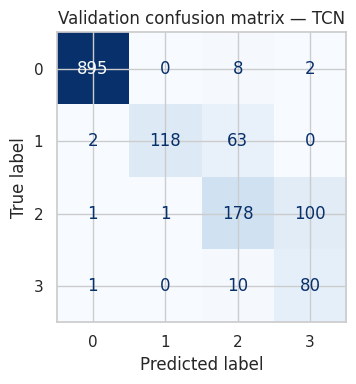

Inference ms / window: 0.0741


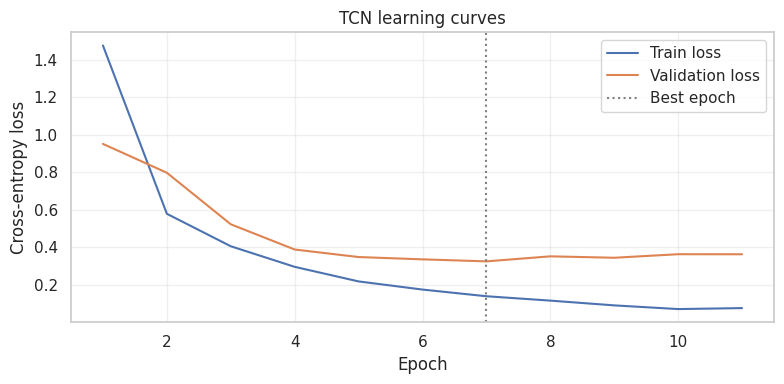

In [ ]:
# Baseline TCN: same windows, early stopping, metrics as MLP / CNN / RNN family
if RUN_DEEP_MODELS:
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    model = build_tcn(**TCN_DEFAULT)
    model.summary()
    history, pred, seconds = fit_and_predict(model)
    models['TCN'] = model
    histories['TCN'] = history
    row = evaluate_validation('TCN', pred, seconds, model.count_params())
    row['Inference ms / window'] = inference_ms_per_window(model, X_val)   # updates the entry in results
    print('Inference ms / window:', round(row['Inference ms / window'], 4))

    h = history.history
    plt.figure(figsize=(8, 4))
    plt.plot(np.arange(1, len(h['loss']) + 1), h['loss'], label='Train loss')
    plt.plot(np.arange(1, len(h['val_loss']) + 1), h['val_loss'], label='Validation loss')
    plt.axvline(np.argmin(h['val_loss']) + 1, color='grey', ls=':', label='Best epoch')
    plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss'); plt.title('TCN learning curves')
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
else:
    print('Neural models skipped. Change RUN_DEEP_MODELS to True to run.')

### HPO protocol for the assigned RNN and TCN models (defined before results)

Both searches use the existing chronological training/validation split and the exact same X_train, X_val, y_train_idx, and y_val_idx windows. The sealed test partition is not used.

| Item | SimpleRNN search | TCN search |
|---|---|---|
| Hyperparameters | units ∈ {(32,16), (64,32)}; dropout ∈ {0.0, 0.2}; learning rate ∈ {0.001, 0.0005} | kernel size ∈ {2,3}; filters ∈ {16,32}; dilations ∈ {(1,2,4),(1,2,4,8)}; dropout ∈ {0.0,0.2}; learning rate fixed at 0.001 |
| Search budget | 8 combinations | 16 possible combinations; 4 are skipped when receptive field < LOOKBACK, leaving 12 trained trials |
| Maximum epochs | 20 per trial | 20 per trial |
| Objective | Validation macro-F1 over all occupancy classes (`zero_division=0`) | Same |
| Stopping rule | EarlyStopping on `val_loss`, patience 4, restore best weights | Same |
| Tie-break | Higher macro-F1; if tied, fewer trainable parameters | Same |


Total maximum budget: 20 trained trials (8 SimpleRNN + 12 TCN). Training time is recorded for every trial. The validation set is used for early stopping and HPO selection; it is not a substitute for the sealed final test set.

### TCN grid search — protocol (defined before results)

| Item | Setting |
|---|---|
| Search space | `kernel_size` ∈ {2, 3}; `filters` ∈ {16, 32}; `dilations` ∈ {(1,2,4), (1,2,4,8)}; `dropout` ∈ {0.0, 0.2}; lr = 0.001 |
| Constraint | Skip any configuration with receptive field < LOOKBACK (20) |
| Budget | 16 combinations, at most 12 trained (4 skipped by the RF rule); max EPOCHS per trial |
| Objective | Validation macro-F1 (classes are imbalanced) |
| Stopping rule | EarlyStopping on validation loss, patience 4, best weights restored |
| Tie-break | Fewer parameters wins |
| Data | Training windows to fit, validation windows to score. Test set stays sealed. |
"""

In [ ]:
# B9. TCN grid search (validation only)
from itertools import product
import json

tcn_grid = {'kernel_size': [2, 3], 'filters': [16, 32],
            'dilations': [(1, 2, 4), (1, 2, 4, 8)], 'dropout': [0.0, 0.2]}
tcn_trials = []
best_tcn_model, best_tcn_config, best_tcn_key = None, None, None

if RUN_DEEP_MODELS and RUN_GRID_SEARCH:
    for k, f, dil, dr in product(tcn_grid['kernel_size'], tcn_grid['filters'],
                                 tcn_grid['dilations'], tcn_grid['dropout']):
        rf = tcn_receptive_field(k, dil)
        if rf < LOOKBACK:
            print(f'Skip k={k}, dilations={dil}: RF={rf} < LOOKBACK={LOOKBACK}')
            continue
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
        cfg = dict(filters=f, kernel_size=k, dilations=dil, dropout=dr, lr=0.001)
        model = build_tcn(**cfg)
        history, pred, elapsed = fit_and_predict(model)
        macro_f1 = f1_score(y_val, pred, labels=all_classes, average='macro', zero_division=0)
        params = model.count_params()
        tcn_trials.append({'trial': len(tcn_trials) + 1, 'kernel_size': k, 'filters': f,
                           'dilations': str(dil), 'dropout': dr, 'receptive_field': rf,
                           'validation_macro_f1': macro_f1,
                           'validation_accuracy': accuracy_score(y_val, pred),
                           'epochs': len(history.history['loss']),
                           'parameters': params, 'training_seconds': elapsed})
        key = (macro_f1, -params)                         # higher F1 first, then fewer params
        if best_tcn_key is None or key > best_tcn_key:
            best_tcn_key, best_tcn_config, best_tcn_model = key, cfg, model
            best_tcn_seconds = elapsed

    tcn_trials_df = pd.DataFrame(tcn_trials)
    display(tcn_trials_df.sort_values(['validation_macro_f1', 'parameters'],
                                      ascending=[False, True]).round(4))
    print('Best TCN configuration:', best_tcn_config)
else:
    print('TCN grid search skipped by configuration.')

Skip k=2, dilations=(1, 2, 4): RF=15 < LOOKBACK=20
Skip k=2, dilations=(1, 2, 4): RF=15 < LOOKBACK=20
Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.1516 - loss: 2.2322 - val_accuracy: 0.6881 - val_loss: 0.9381
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7555 - loss: 0.7927 - val_accuracy: 0.6792 - val_loss: 0.8538
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8020 - loss: 0.7498 - val_accuracy: 0.7039 - val_loss: 0.7447
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8178 - loss: 0.6449 - val_accuracy: 0.7409 - val_loss: 0.6294
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8331 - loss: 0.5459 - val_accuracy: 0.7711 - val_loss: 0.5599
Epoch 6/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8441 - loss: 0.4688 - val_accuracy: 0.7875 - val_loss: 0.5194
Epoch 7/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8625 - loss: 0.4064 - val_accuracy: 0.7971 - val_loss: 0.4916
Epoch 8/20

,trial,kernel_size,filters,dilations,dropout,receptive_field,validation_macro_f1,validation_accuracy,epochs,parameters,training_seconds
6,7,3,16,"(1, 2, 4, 8)",0.0,61,0.8675,0.9308,20,7124,26.5620
7,8,3,16,"(1, 2, 4, 8)",0.2,61,0.8473,0.8992,20,7124,30.9427
11,12,3,32,"(1, 2, 4, 8)",0.2,61,0.8452,0.9232,20,24996,30.4360
0,1,2,16,"(1, 2, 4, 8)",0.0,31,0.8410,0.9130,20,5012,41.0400
3,4,2,32,"(1, 2, 4, 8)",0.2,31,0.8340,0.9150,20,17188,29.7872
8,9,3,32,"(1, 2, 4)",0.0,29,0.8013,0.8924,18,18660,19.3889
1,2,2,16,"(1, 2, 4, 8)",0.2,31,0.7995,0.8890,20,5012,31.0851
9,10,3,32,"(1, 2, 4)",0.2,29,0.7712,0.8787,15,18660,24.8625
4,5,3,16,"(1, 2, 4)",0.0,29,0.7633,0.8746,20,5492,42.5087
5,6,3,16,"(1, 2, 4)",0.2,29,0.7509,0.9034,20,5492,22.9189


Best TCN configuration: {'filters': 16, 'kernel_size': 3, 'dilations': (1, 2, 4, 8), 'dropout': 0.0, 'lr': 0.001}


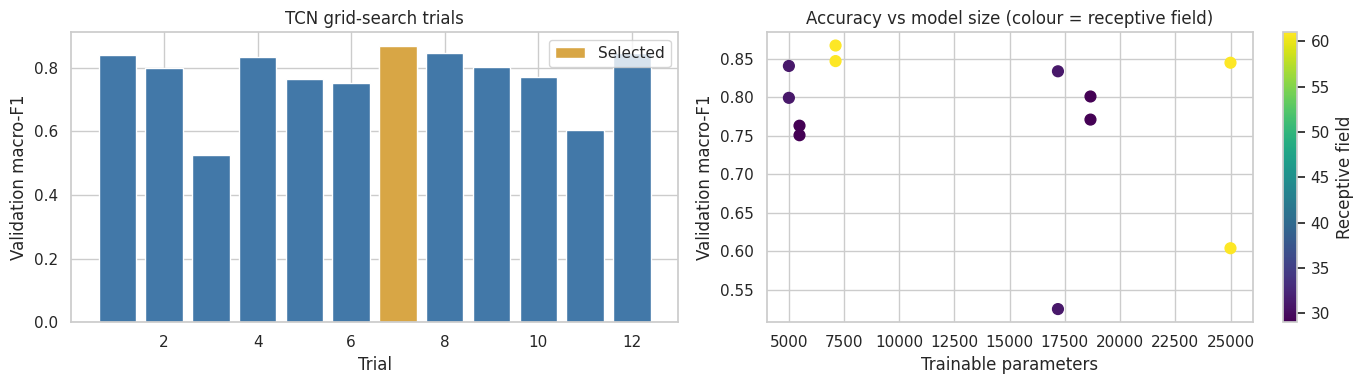


 TCN (grid selected)


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,TCN (grid selected),0.9308,0.8675,0.8773,7124,26.562


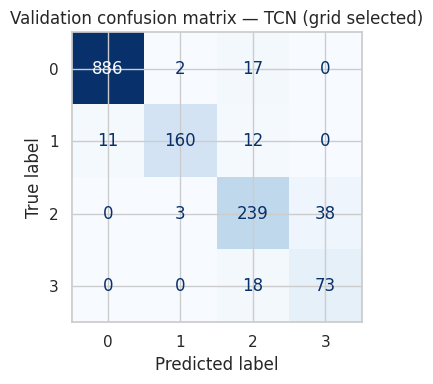

Saved: ['preprocessing.joblib', 'tcn_best.keras', 'tcn_best_config.json']


In [ ]:
# HPO evidence plot + evaluate and checkpoint the selected TCN
if RUN_DEEP_MODELS and RUN_GRID_SEARCH and len(tcn_trials):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    axes[0].bar(tcn_trials_df['trial'], tcn_trials_df['validation_macro_f1'], color='#4278a8')
    best_trial = tcn_trials_df.loc[
        tcn_trials_df.sort_values(['validation_macro_f1', 'parameters'],
                                  ascending=[False, True]).index[0], 'trial']
    axes[0].bar(best_trial, tcn_trials_df.set_index('trial').loc[best_trial, 'validation_macro_f1'],
                color='#d8a645', label='Selected')
    axes[0].set(xlabel='Trial', ylabel='Validation macro-F1', title='TCN grid-search trials')
    axes[0].legend()
    sc = axes[1].scatter(tcn_trials_df['parameters'], tcn_trials_df['validation_macro_f1'],
                         c=tcn_trials_df['receptive_field'], cmap='viridis', s=60)
    axes[1].set(xlabel='Trainable parameters', ylabel='Validation macro-F1',
                title='Accuracy vs model size (colour = receptive field)')
    plt.colorbar(sc, ax=axes[1], label='Receptive field')
    plt.tight_layout(); plt.show()

    best_pred = classes[best_tcn_model.predict(X_val, verbose=0).argmax(axis=1)]
    row = evaluate_validation('TCN (grid selected)', best_pred, best_tcn_seconds,
                              best_tcn_model.count_params())
    row['Inference ms / window'] = inference_ms_per_window(best_tcn_model, X_val)
    models['TCN (grid selected)'] = best_tcn_model

    # Checkpoint model + configuration + preprocessing state for Stage 3
    import joblib
    CKPT_DIR = Path('checkpoints'); CKPT_DIR.mkdir(exist_ok=True)
    best_tcn_model.save(CKPT_DIR / 'tcn_best.keras')
    with open(CKPT_DIR / 'tcn_best_config.json', 'w') as fh:
        json.dump({**best_tcn_config, 'dilations': list(best_tcn_config['dilations']),
                   'receptive_field': tcn_receptive_field(best_tcn_config['kernel_size'],
                                                          best_tcn_config['dilations']),
                   'lookback': LOOKBACK, 'horizon': HORIZON, 'seed': SEED,
                   'feature_cols': feature_cols, 'classes': [int(c) for c in classes],
                   'validation_macro_f1': float(best_tcn_key[0])}, fh, indent=2)
    joblib.dump({'imputer': imputer, 'scaler': scaler}, CKPT_DIR / 'preprocessing.joblib')
    print('Saved:', sorted(p.name for p in CKPT_DIR.iterdir()))


### Assigned-model results and checkpoints: bestSimpleRNN and best CNN

This cell compares the best RNN and TCN trials using the same validation windows, records parameter counts, training time and inference latency, and saves each best model separately. It does not access the test set.

In [ ]:
# B10. Compare the best assigned RNN and TCN trials; save model + config + preprocessing
import joblib, json, time
from pathlib import Path

assert best_rnn_model is not None, "Run the SimpleRNN HPO cell first."
assert best_tcn_model is not None, "Run the TCN HPO cell (B9) first."

def measure_inference_ms(model, X, repeats=5):
    # Warm-up then median whole-validation prediction time / number of windows.
    model.predict(X[:min(BATCH_SIZE, len(X))], verbose=0)
    elapsed = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        model.predict(X, batch_size=BATCH_SIZE, verbose=0)
        elapsed.append(time.perf_counter() - t0)
    return 1000.0 * float(np.median(elapsed)) / len(X)

assigned_candidates = [
    ('SimpleRNN (HPO selected)', best_rnn_model, best_rnn_config,
     best_rnn_seconds, best_rnn_key[0]),
    ('TCN (HPO selected)', best_tcn_model, best_tcn_config,
     best_tcn_seconds, best_tcn_key[0])
]

assigned_rows = []
for name, model_obj, config, train_seconds, recorded_f1 in assigned_candidates:
    pred_idx = model_obj.predict(X_val, batch_size=BATCH_SIZE, verbose=0).argmax(axis=1)
    pred = classes[pred_idx]
    assigned_rows.append({
        'Model': name,
        'Configuration': str(config),
        'Validation accuracy': accuracy_score(y_val, pred),
        'Validation macro-F1': f1_score(
            y_val, pred, labels=all_classes, average='macro', zero_division=0
        ),
        'Trainable parameters': int(model_obj.count_params()),
        'Training seconds': float(train_seconds),
        'Inference ms / window': measure_inference_ms(model_obj, X_val)
    })

assigned_comparison = pd.DataFrame(assigned_rows).sort_values(
    ['Validation macro-F1', 'Trainable parameters'],
    ascending=[False, True]
).reset_index(drop=True)
display(assigned_comparison.round(5))

# Best assigned architecture is chosen from measured validation results, not its name.
winner = assigned_comparison.iloc[0]
print('Best of the two assigned models:', winner['Model'])
print('Validation macro-F1:', round(float(winner['Validation macro-F1']), 5))

# Save both models, not just the winner, so the group can inspect/reuse either one.
CKPT_DIR = Path('checkpoints')
CKPT_DIR.mkdir(exist_ok=True)

def save_keras_candidate(model_obj, config, model_name, metrics, file_stem):
    model_file = f'{file_stem}.keras'
    model_obj.save(CKPT_DIR / model_file)
    config_out = dict(config)
    if 'dilations' in config_out:
        config_out['dilations'] = list(config_out['dilations'])
        config_out['receptive_field'] = tcn_receptive_field(
            config_out['kernel_size'], tuple(config_out['dilations'])
        )
    config_out.update({
        'model_name': model_name,
        'model_file': model_file,
        'lookback': int(LOOKBACK),
        'horizon': int(HORIZON),
        'seed': int(SEED),
        'feature_columns': list(feature_cols),
        'classes': [int(c) for c in classes],
        'validation_metrics': metrics,
        'selection_metric': 'validation_macro_f1',
        'stopping_rule': 'EarlyStopping(monitor=val_loss, patience=4, restore_best_weights=True)'
    })
    with open(CKPT_DIR / f'{file_stem}_config.json', 'w') as f:
        json.dump(config_out, f, indent=2)

for name, model_obj, config, train_seconds, _ in assigned_candidates:
    matching = assigned_comparison.loc[assigned_comparison['Model'] == name].iloc[0]
    metrics = {
        'accuracy': float(matching['Validation accuracy']),
        'macro_f1': float(matching['Validation macro-F1']),
        'trainable_parameters': int(matching['Trainable parameters']),
        'training_seconds': float(matching['Training seconds']),
        'inference_ms_per_window': float(matching['Inference ms / window'])
    }
    stem = 'simplernn_best' if name.startswith('SimpleRNN') else 'tcn_best'
    save_keras_candidate(model_obj, config, name, metrics, stem)

# Save fitted training-only preprocessing state and feature/window metadata.
joblib.dump({
    'imputer': imputer,
    'scaler': scaler,
    'feature_columns': list(feature_cols),
    'sensor_columns': list(safe_sensor_cols),
    'calendar_columns': list(calendar_cols),
    'target_column': TARGET,
    'lookback': int(LOOKBACK),
    'horizon': int(HORIZON),
    'max_interval_seconds': float(MAX_INTERVAL.total_seconds())
}, CKPT_DIR / 'preprocessing.joblib')

# Keep auditable trial evidence and the side-by-side assigned-model comparison.
rnn_trials_df.to_csv(CKPT_DIR / 'simplernn_hpo_trials.csv', index=False)
tcn_trials_df.to_csv(CKPT_DIR / 'tcn_hpo_trials.csv', index=False)
assigned_comparison.to_csv(CKPT_DIR / 'rnn_tcn_comparison.csv', index=False)

print('Saved checkpoint artifacts:')
for saved_file in sorted(CKPT_DIR.iterdir()):
    print(' -', saved_file.name)

## 10. Stage 2 comparison, result interpretation and risks
All reported metrics below use the same validation target timestamps. Report improvement relative to majority macro-F1. A **negative improvement** means worse than majority. Class-imbalance handling and the very short coverage are unresolved risks until tested.

In [ ]:
comparison = pd.DataFrame(results).drop_duplicates(subset='Model',keep='last')
base = float(comparison.loc[comparison['Model']=='Majority','Macro F1'].iloc[0])
comparison['Macro F1 gain vs majority (%)'] = 100*(comparison['Macro F1']-base)/base if base else np.nan
comparison = comparison.sort_values('Macro F1',ascending=False)
display(comparison.round(4))
print('Best validation model:',comparison.iloc[0]['Model'])


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds,Inference ms / window,Macro F1 gain vs majority (%)
1,Persistence,0.9945,0.9899,0.9894,0,0.0000,NaN,417.1598
10,TCN (grid selected),0.9308,0.8675,0.8773,7124,26.5620,0.0771,353.2333
5,CNN (grid selected),0.9191,0.8284,0.8566,1828,12.7287,NaN,332.7598
2,Random forest,0.9095,0.8191,0.8701,150,0.8914,NaN,327.9428
7,LSTM,0.8917,0.7944,0.8204,34308,12.9633,NaN,315.0077
4,CNN,0.8862,0.7882,0.8406,5188,16.8224,NaN,311.7622
3,MLP,0.8684,0.7602,0.8424,12964,7.9979,NaN,297.1619
9,TCN,0.8711,0.7551,0.7871,18660,37.0480,0.0741,294.4692
8,GRU,0.8300,0.6813,0.7712,26052,5.2289,NaN,255.9372
6,RNN,0.8225,0.6671,0.7226,8676,12.3426,NaN,248.5035


Best validation model: Persistence


In [ ]:
# Local/Colab dependency report for the README/requirements file.
import sklearn, tensorflow
print('pandas=='+pd.__version__)
print('numpy=='+np.__version__)
print('matplotlib=='+plt.matplotlib.__version__)
print('seaborn=='+sns.__version__)
print('scikit-learn=='+sklearn.__version__)
print('tensorflow=='+tensorflow.__version__)
print('Seed:',SEED,'lookback:',LOOKBACK,'horizon:',HORIZON)

pandas==2.2.3
numpy==2.4.6
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
tensorflow==2.21.0
Seed: 42 lookback: 20 horizon: 2


All evaluated machine-learning and deep-learning models substantially outperformed the majority-class baseline. However, the persistence baseline achieved the strongest validation performance, with macro-F1 of 0.9899.

This suggests that short-term occupancy forecasting is strongly influenced by temporal persistence. More complex models may be more useful for longer forecasting horizons or for anticipating changes in room occupancy.

Important limitations include class imbalance, short recording coverage, discontinuous timestamps, changing class distributions and the restricted temporal coverage of the revised training and validation periods.

We plan to explore adding larger training weights to windows where occupany changes but this might redduce overall accuracy Or using longer lookbacks which may help identify slower changes in co2

#**Conclusion**

Under our current one-minute-ahead forecasting horizon, persistence is the strongest baseline because occupancy doesn't change so frequently.